# TUGAS BESAR DKA: IMPLEMENTASI FUZZY LOGIC
## Penilaian Risiko Kredit Menggunakan Fuzzy Mamdani dan Fuzzy Sugeno

**Dataset:** Credit Risk Dataset  
**Sumber:** https://www.kaggle.com/datasets/laotse/credit-risk-dataset

---
### Anggota Kelompok:
| No | Nama | NIM |
|----|------|-----|
| 1  | [Muhammad Aufa Ahsan] | [103012400115] |
| 2  | [Muhammad Rafli Ramadhan] | [103012400115] |
| 3  | [Muhammad Rasya Ardito] | [103012400064] |

**Kelas:** [IF-48-02]  


## 1. Import Library

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
import matplotlib.cm as cm
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn hanya untuk evaluasi metrik (bukan fuzzy)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
print("✅ Semua library berhasil diimport")
print(f"Numpy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")


✅ Semua library berhasil diimport
Numpy version: 1.26.4
Pandas version: 2.2.2


## 2. Load dan Eksplorasi Dataset

**Dataset:** Credit Risk Dataset dari Kaggle  
**Link:** https://www.kaggle.com/datasets/laotse/credit-risk-dataset  

Dataset ini berisi informasi tentang peminjam dan status pinjaman mereka. Terdiri dari 12 variabel dengan 5.000 baris data.


In [5]:
# Load dataset dengan path yang aman
from pathlib import Path

BASE_DIR = Path.cwd()
DATASET_CANDIDATES = [
    BASE_DIR / 'credit_risk_dataset.csv',
    BASE_DIR / 'data' / 'credit_risk_dataset.csv',
    BASE_DIR / 'dataset' / 'credit_risk_dataset.csv',
]

dataset_path = next((p for p in DATASET_CANDIDATES if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Simpan credit_risk_dataset.csv di folder yang sama dengan notebook, "
        "atau di folder data/ maupun dataset/."
    )

df = pd.read_csv(dataset_path)

print("=" * 60)
print("INFORMASI DATASET")
print("=" * 60)
print(f"File dataset    : {dataset_path}")
print(f"Jumlah baris    : {df.shape[0]:,}")
print(f"Jumlah kolom    : {df.shape[1]}")
print(f"\nVariabel Input  : 11 kolom")
print(f"Variabel Output : loan_status (0=Tidak Default, 1=Default)")
print("\n--- Kolom Dataset ---")
print(df.dtypes)
print("\n--- 5 Baris Pertama ---")
df.head()


INFORMASI DATASET
File dataset    : C:\Users\mhmmd\Documents\tubes dkaa\credit_risk_dataset.csv
Jumlah baris    : 5,000
Jumlah kolom    : 12

Variabel Input  : 11 kolom
Variabel Output : loan_status (0=Tidak Default, 1=Default)

--- Kolom Dataset ---
person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length               int64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object

--- 5 Baris Pertama ---


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,58,85149,RENT,5,VENTURE,C,29834,18.42,1,0.35,N,19
1,71,64497,MORTGAGE,12,PERSONAL,A,20801,10.77,1,0.32,Y,12
2,48,30448,RENT,1,DEBTCONSOLIDATION,A,7807,15.66,0,0.26,N,29
3,34,80300,MORTGAGE,6,MEDICAL,B,29751,16.08,1,0.37,N,8
4,62,17264,MORTGAGE,8,MEDICAL,B,34657,5.84,0,2.01,N,2


In [6]:
# Statistik deskriptif
print("=== STATISTIK DESKRIPTIF ===")
print(df.describe().round(2).to_string())


=== STATISTIK DESKRIPTIF ===
       person_age  person_income  person_emp_length  loan_amnt  loan_int_rate  loan_status  loan_percent_income  cb_person_cred_hist_length
count     5000.00        5000.00            5000.00    5000.00        5000.00      5000.00              5000.00                     5000.00
mean        47.22       45820.46               5.80   17849.53          14.35         0.52                 0.64                       15.80
std         15.80       35669.67               3.63    9809.04           5.14         0.50                 0.69                        8.06
min         20.00        2958.00               0.00     514.00           5.43         0.00                 0.00                        2.00
25%         34.00       22333.50               3.00    9672.25           9.90         0.00                 0.21                        9.00
50%         47.00       35611.50               5.00   17748.50          14.30         1.00                 0.44                    

In [7]:
# Cek missing values
print("=== MISSING VALUES ===")
print(df.isnull().sum())
print(f"\nTotal missing: {df.isnull().sum().sum()}")

# Distribusi target
print("\n=== DISTRIBUSI TARGET (loan_status) ===")
vc = df['loan_status'].value_counts()
print(f"Tidak Default (0): {vc[0]:,} ({vc[0]/len(df)*100:.1f}%)")
print(f"Default (1)      : {vc[1]:,} ({vc[1]/len(df)*100:.1f}%)")


=== MISSING VALUES ===
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Total missing: 0

=== DISTRIBUSI TARGET (loan_status) ===
Tidak Default (0): 2,393 (47.9%)
Default (1)      : 2,607 (52.1%)


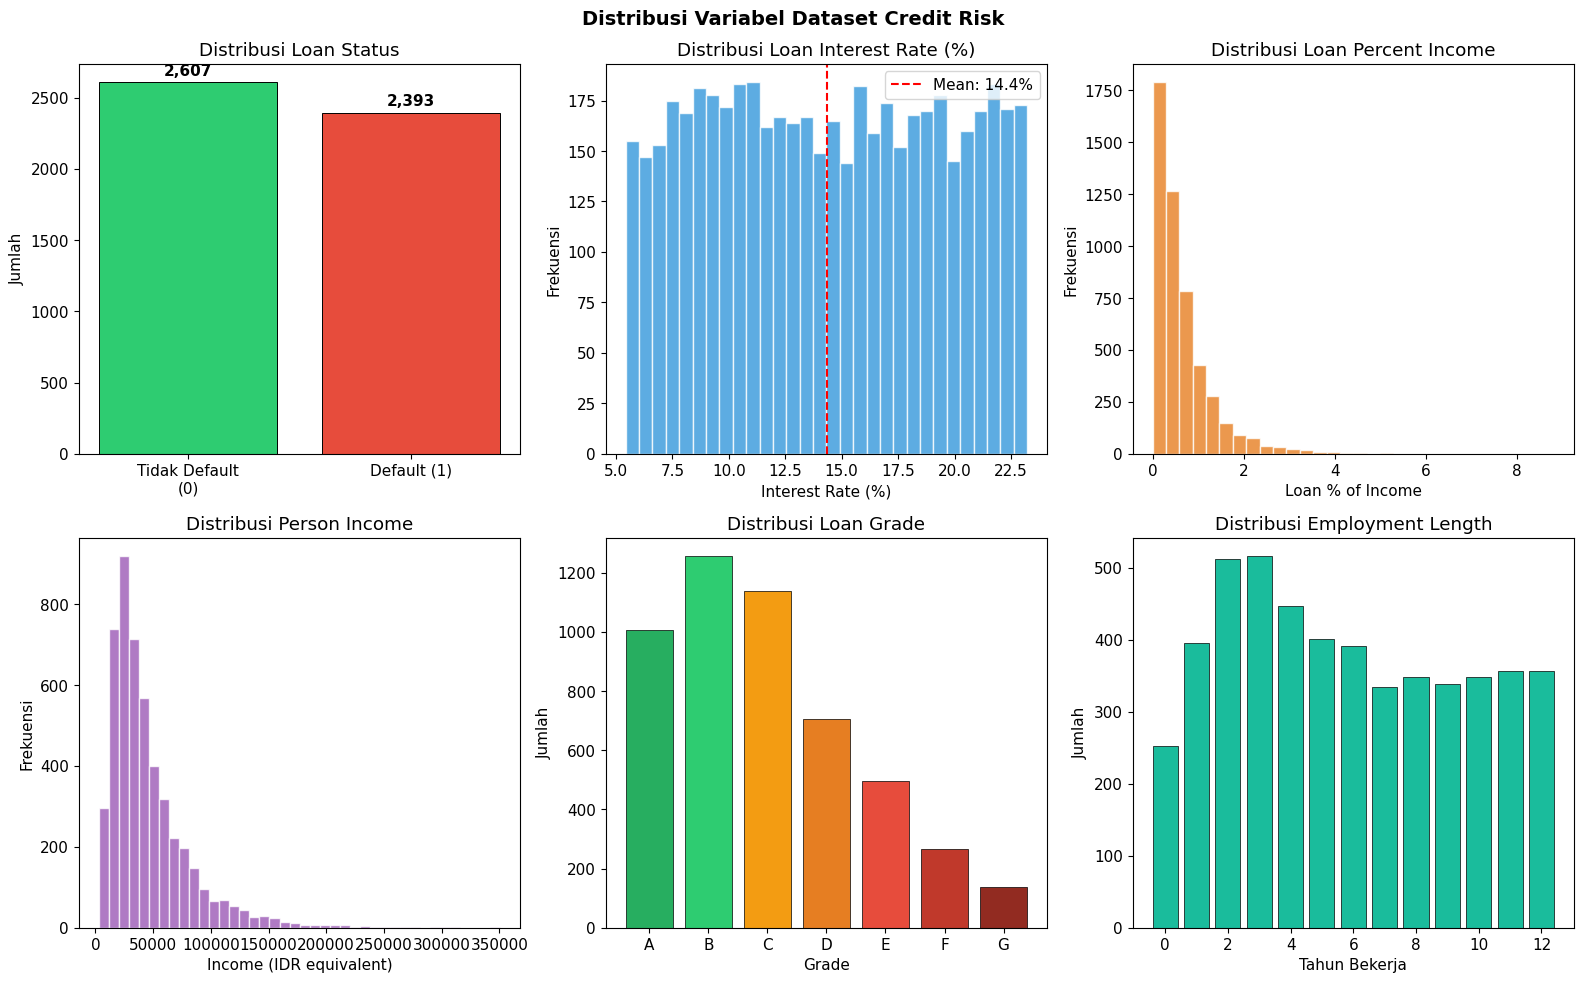

Visualisasi distribusi dataset selesai.


In [8]:
# Visualisasi Distribusi Dataset
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Distribusi Variabel Dataset Credit Risk', fontsize=14, fontweight='bold')

# 1. Loan Status
ax1 = axes[0, 0]
colors = ['#2ecc71', '#e74c3c']
bars = ax1.bar(['Tidak Default\n(0)', 'Default (1)'], 
               df['loan_status'].value_counts().values,
               color=colors, edgecolor='black', linewidth=0.7)
for bar, val in zip(bars, df['loan_status'].value_counts().values):
    ax1.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 30,
             f'{val:,}', ha='center', va='bottom', fontweight='bold')
ax1.set_title('Distribusi Loan Status')
ax1.set_ylabel('Jumlah')

# 2. Loan Interest Rate
ax2 = axes[0, 1]
ax2.hist(df['loan_int_rate'], bins=30, color='#3498db', edgecolor='white', alpha=0.8)
ax2.set_title('Distribusi Loan Interest Rate (%)')
ax2.set_xlabel('Interest Rate (%)')
ax2.set_ylabel('Frekuensi')
ax2.axvline(df['loan_int_rate'].mean(), color='red', linestyle='--', 
            label=f'Mean: {df["loan_int_rate"].mean():.1f}%')
ax2.legend()

# 3. Loan Percent Income
ax3 = axes[0, 2]
ax3.hist(df['loan_percent_income'], bins=30, color='#e67e22', edgecolor='white', alpha=0.8)
ax3.set_title('Distribusi Loan Percent Income')
ax3.set_xlabel('Loan % of Income')
ax3.set_ylabel('Frekuensi')

# 4. Person Income (log scale)
ax4 = axes[1, 0]
ax4.hist(df['person_income'], bins=40, color='#9b59b6', edgecolor='white', alpha=0.8)
ax4.set_title('Distribusi Person Income')
ax4.set_xlabel('Income (IDR equivalent)')
ax4.set_ylabel('Frekuensi')

# 5. Loan Grade
ax5 = axes[1, 1]
grade_counts = df['loan_grade'].value_counts().sort_index()
ax5.bar(grade_counts.index, grade_counts.values, 
        color=['#27ae60','#2ecc71','#f39c12','#e67e22','#e74c3c','#c0392b','#922b21'],
        edgecolor='black', linewidth=0.5)
ax5.set_title('Distribusi Loan Grade')
ax5.set_xlabel('Grade')
ax5.set_ylabel('Jumlah')

# 6. Employment Length
ax6 = axes[1, 2]
emp_counts = df['person_emp_length'].value_counts().sort_index()
ax6.bar(emp_counts.index, emp_counts.values, color='#1abc9c', edgecolor='black', linewidth=0.5)
ax6.set_title('Distribusi Employment Length')
ax6.set_xlabel('Tahun Bekerja')
ax6.set_ylabel('Jumlah')

plt.tight_layout()
plt.savefig('distribusi_dataset.png', bbox_inches='tight', dpi=100)
plt.show()
print("Visualisasi distribusi dataset selesai.")


## 3. Preprocessing Data

Untuk implementasi Fuzzy Logic, kita memilih **5 variabel input numerik** yang paling relevan untuk penilaian risiko kredit:

| Variabel | Deskripsi | Range |
|----------|-----------|-------|
| `loan_int_rate` | Suku bunga pinjaman (%) | 5.42 - 23.22 |
| `loan_percent_income` | Rasio pinjaman terhadap pendapatan | 0 - 1 |
| `person_emp_length` | Lama bekerja (tahun) | 0 - 12+ |
| `loan_amnt` | Jumlah pinjaman | 500 - 35.000 |
| `cb_person_cred_hist_length` | Panjang riwayat kredit (tahun) | 2 - 30 |

**Output:** `loan_status` → Risiko Kredit (0-100, threshold 50 = Default)


In [9]:
# Preprocessing: Pilih 5 variabel input numerik + output
feature_cols = ['loan_int_rate', 'loan_percent_income', 'person_emp_length', 
                'loan_amnt', 'cb_person_cred_hist_length']
target_col = 'loan_status'

# Drop rows dengan missing values pada kolom yang digunakan
df_clean = df[feature_cols + [target_col]].dropna().reset_index(drop=True)

print(f"Data setelah preprocessing: {df_clean.shape[0]:,} baris")
print(f"\n--- Statistik Variabel Input ---")
print(df_clean[feature_cols].describe().round(3).to_string())

# Normalize loan_amnt ke 0-1 range untuk kemudahan interpretasi
df_clean['loan_amnt_norm'] = (df_clean['loan_amnt'] - df_clean['loan_amnt'].min()) /                               (df_clean['loan_amnt'].max() - df_clean['loan_amnt'].min())

print("\n✅ Preprocessing selesai")
print(f"Distribusi target: {df_clean[target_col].value_counts().to_dict()}")


Data setelah preprocessing: 5,000 baris

--- Statistik Variabel Input ---
       loan_int_rate  loan_percent_income  person_emp_length  loan_amnt  cb_person_cred_hist_length
count       5000.000             5000.000           5000.000   5000.000                    5000.000
mean          14.352                0.644              5.795  17849.532                      15.803
std            5.137                0.692              3.632   9809.040                       8.059
min            5.430                0.000              0.000    514.000                       2.000
25%            9.898                0.208              3.000   9672.250                       9.000
50%           14.305                0.440              5.000  17748.500                      16.000
75%           18.822                0.840              9.000  26094.750                      23.000
max           23.220                8.820             12.000  34981.000                      29.000

✅ Preprocessing selesai
D

## 4. Desain Variabel Linguistik dan Fungsi Keanggotaan

### 4.1 Definisi Variabel Linguistik

Berikut adalah variabel linguistik yang didesain untuk sistem Fuzzy Logic penilaian risiko kredit:

#### Variabel Input:
| No | Variabel | Term Linguistik |
|----|----------|-----------------|
| 1 | Interest Rate (%) | Rendah, Sedang, Tinggi |
| 2 | Loan to Income Ratio | Kecil, Sedang, Besar |
| 3 | Employment Length (thn) | Baru, Menengah, Senior |
| 4 | Loan Amount (ribuan) | Kecil, Sedang, Besar |
| 5 | Credit History Length (thn) | Pendek, Sedang, Panjang |

#### Variabel Output:
| Variabel | Term Linguistik |
|----------|-----------------|
| Risiko Kredit (0-100) | Sangat Rendah, Rendah, Sedang, Tinggi, Sangat Tinggi |


In [10]:
# ============================================================
# FUNGSI KEANGGOTAAN (Membership Functions) - FROM SCRATCH
# ============================================================

def trimf(x, a, b, c):
    """Triangular Membership Function"""
    x = np.asarray(x, dtype=float)
    result = np.zeros_like(x)
    # Left slope
    mask1 = (x >= a) & (x <= b)
    if b != a:
        result[mask1] = (x[mask1] - a) / (b - a)
    # Right slope
    mask2 = (x > b) & (x <= c)
    if c != b:
        result[mask2] = (c - x[mask2]) / (c - b)
    # Peak
    result[x == b] = 1.0
    return np.clip(result, 0, 1)

def trapmf(x, a, b, c, d):
    """Trapezoidal Membership Function"""
    x = np.asarray(x, dtype=float)
    result = np.zeros_like(x)
    # Left slope
    mask1 = (x >= a) & (x < b)
    if b != a:
        result[mask1] = (x[mask1] - a) / (b - a)
    # Flat top
    mask2 = (x >= b) & (x <= c)
    result[mask2] = 1.0
    # Right slope
    mask3 = (x > c) & (x <= d)
    if d != c:
        result[mask3] = (d - x[mask3]) / (d - c)
    return np.clip(result, 0, 1)

def gaussmf(x, mean, sigma):
    """Gaussian Membership Function"""
    x = np.asarray(x, dtype=float)
    return np.exp(-0.5 * ((x - mean) / sigma) ** 2)

print("✅ Fungsi keanggotaan (trimf, trapmf, gaussmf) berhasil didefinisikan")

# Test fungsi keanggotaan
x_test = np.linspace(0, 10, 100)
mf_tri = trimf(x_test, 2, 5, 8)
mf_trap = trapmf(x_test, 1, 3, 7, 9)
print(f"Max trimf: {mf_tri.max():.2f}, Max trapmf: {mf_trap.max():.2f}")


✅ Fungsi keanggotaan (trimf, trapmf, gaussmf) berhasil didefinisikan
Max trimf: 0.98, Max trapmf: 1.00


In [11]:
# ============================================================
# DEFINISI FUNGSI KEANGGOTAAN UNTUK SETIAP VARIABEL
# ============================================================

# ---------- INPUT 1: Interest Rate (5.42 - 23.22%) ----------
def mf_int_rate_rendah(x):
    return trapmf(x, 5, 5, 8, 12)

def mf_int_rate_sedang(x):
    return trimf(x, 9, 14, 18)

def mf_int_rate_tinggi(x):
    return trapmf(x, 16, 19, 24, 24)

# ---------- INPUT 2: Loan Percent Income (0 - 1) ----------
def mf_lpi_kecil(x):
    return trapmf(x, 0, 0, 0.1, 0.2)

def mf_lpi_sedang(x):
    return trimf(x, 0.15, 0.3, 0.45)

def mf_lpi_besar(x):
    return trapmf(x, 0.35, 0.5, 1.0, 1.0)

# ---------- INPUT 3: Employment Length (0 - 12+ tahun) ----------
def mf_emp_baru(x):
    return trapmf(x, 0, 0, 1, 3)

def mf_emp_menengah(x):
    return trimf(x, 2, 5, 8)

def mf_emp_senior(x):
    return trapmf(x, 7, 10, 13, 13)

# ---------- INPUT 4: Loan Amount (500 - 35000) ----------
def mf_amnt_kecil(x):
    return trapmf(x, 0, 0, 5000, 10000)

def mf_amnt_sedang(x):
    return trimf(x, 7500, 17500, 27500)

def mf_amnt_besar(x):
    return trapmf(x, 25000, 30000, 36000, 36000)

# ---------- INPUT 5: Credit History Length (2 - 30 tahun) ----------
def mf_cred_pendek(x):
    return trapmf(x, 0, 0, 5, 10)

def mf_cred_sedang(x):
    return trimf(x, 7, 15, 22)

def mf_cred_panjang(x):
    return trapmf(x, 19, 24, 31, 31)

# ---------- OUTPUT: Risiko Kredit (0 - 100) ----------
def mf_risk_sangat_rendah(x):
    return trapmf(x, 0, 0, 10, 20)

def mf_risk_rendah(x):
    return trimf(x, 15, 30, 45)

def mf_risk_sedang(x):
    return trimf(x, 35, 50, 65)

def mf_risk_tinggi(x):
    return trimf(x, 55, 70, 85)

def mf_risk_sangat_tinggi(x):
    return trapmf(x, 75, 85, 100, 100)

print("✅ Semua fungsi keanggotaan berhasil didefinisikan")
print("   - Input 1: Interest Rate (rendah, sedang, tinggi)")
print("   - Input 2: Loan-to-Income Ratio (kecil, sedang, besar)")
print("   - Input 3: Employment Length (baru, menengah, senior)")
print("   - Input 4: Loan Amount (kecil, sedang, besar)")
print("   - Input 5: Credit History Length (pendek, sedang, panjang)")
print("   - Output : Risiko Kredit (sangat_rendah, rendah, sedang, tinggi, sangat_tinggi)")


✅ Semua fungsi keanggotaan berhasil didefinisikan
   - Input 1: Interest Rate (rendah, sedang, tinggi)
   - Input 2: Loan-to-Income Ratio (kecil, sedang, besar)
   - Input 3: Employment Length (baru, menengah, senior)
   - Input 4: Loan Amount (kecil, sedang, besar)
   - Input 5: Credit History Length (pendek, sedang, panjang)
   - Output : Risiko Kredit (sangat_rendah, rendah, sedang, tinggi, sangat_tinggi)


### 4.2 Visualisasi Fungsi Keanggotaan

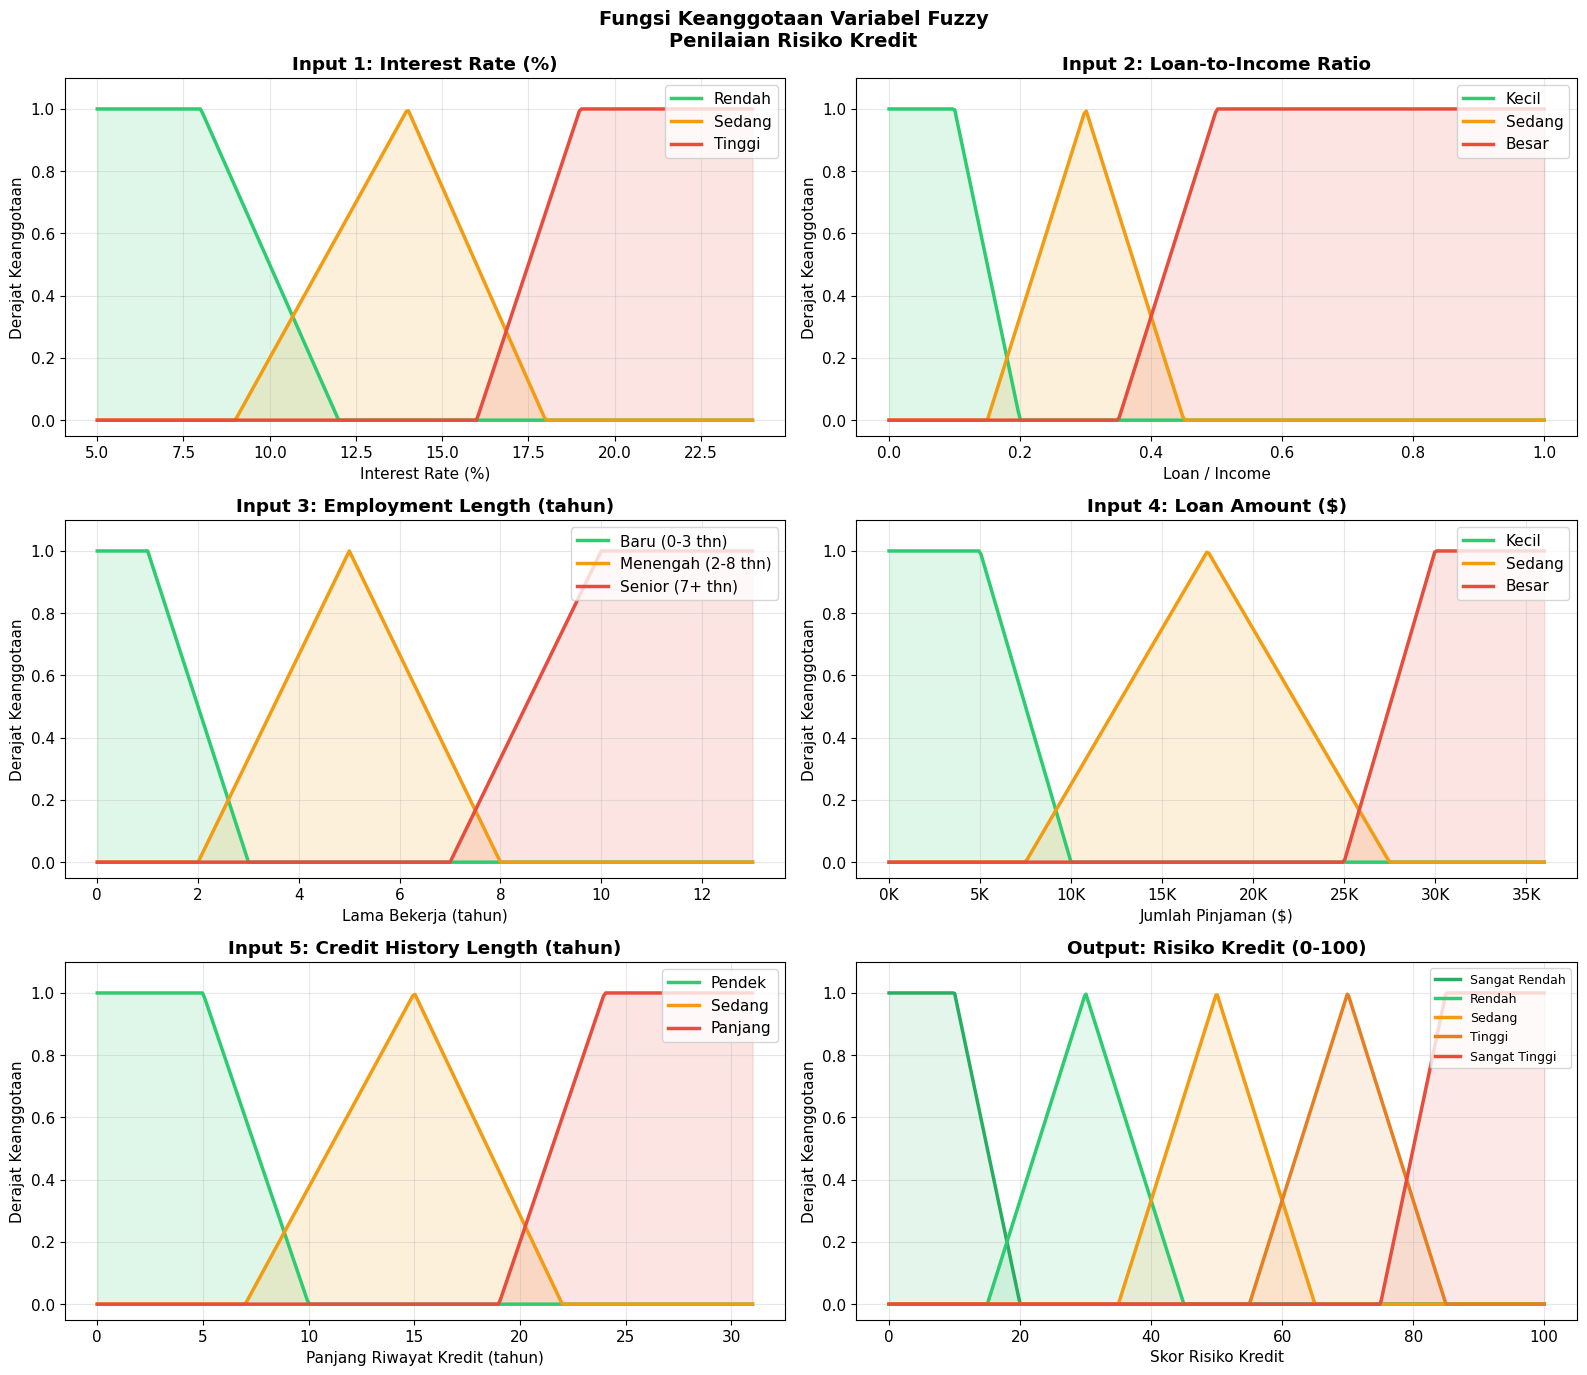

Visualisasi fungsi keanggotaan selesai.


In [12]:
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
fig.suptitle('Fungsi Keanggotaan Variabel Fuzzy\nPenilaian Risiko Kredit', 
             fontsize=14, fontweight='bold')

colors_3 = ['#2ecc71', '#f39c12', '#e74c3c']
colors_5 = ['#27ae60', '#2ecc71', '#f39c12', '#e67e22', '#e74c3c']

# --- Plot 1: Interest Rate ---
ax = axes[0, 0]
x = np.linspace(5, 24, 300)
ax.plot(x, mf_int_rate_rendah(x), color=colors_3[0], lw=2.5, label='Rendah')
ax.plot(x, mf_int_rate_sedang(x), color=colors_3[1], lw=2.5, label='Sedang')
ax.plot(x, mf_int_rate_tinggi(x), color=colors_3[2], lw=2.5, label='Tinggi')
ax.fill_between(x, mf_int_rate_rendah(x), alpha=0.15, color=colors_3[0])
ax.fill_between(x, mf_int_rate_sedang(x), alpha=0.15, color=colors_3[1])
ax.fill_between(x, mf_int_rate_tinggi(x), alpha=0.15, color=colors_3[2])
ax.set_title('Input 1: Interest Rate (%)', fontweight='bold')
ax.set_xlabel('Interest Rate (%)')
ax.set_ylabel('Derajat Keanggotaan')
ax.legend(loc='upper right')
ax.set_ylim(-0.05, 1.1)
ax.grid(True, alpha=0.3)

# --- Plot 2: Loan Percent Income ---
ax = axes[0, 1]
x = np.linspace(0, 1, 300)
ax.plot(x, mf_lpi_kecil(x), color=colors_3[0], lw=2.5, label='Kecil')
ax.plot(x, mf_lpi_sedang(x), color=colors_3[1], lw=2.5, label='Sedang')
ax.plot(x, mf_lpi_besar(x), color=colors_3[2], lw=2.5, label='Besar')
ax.fill_between(x, mf_lpi_kecil(x), alpha=0.15, color=colors_3[0])
ax.fill_between(x, mf_lpi_sedang(x), alpha=0.15, color=colors_3[1])
ax.fill_between(x, mf_lpi_besar(x), alpha=0.15, color=colors_3[2])
ax.set_title('Input 2: Loan-to-Income Ratio', fontweight='bold')
ax.set_xlabel('Loan / Income')
ax.set_ylabel('Derajat Keanggotaan')
ax.legend(loc='upper right')
ax.set_ylim(-0.05, 1.1)
ax.grid(True, alpha=0.3)

# --- Plot 3: Employment Length ---
ax = axes[1, 0]
x = np.linspace(0, 13, 300)
ax.plot(x, mf_emp_baru(x), color=colors_3[0], lw=2.5, label='Baru (0-3 thn)')
ax.plot(x, mf_emp_menengah(x), color=colors_3[1], lw=2.5, label='Menengah (2-8 thn)')
ax.plot(x, mf_emp_senior(x), color=colors_3[2], lw=2.5, label='Senior (7+ thn)')
ax.fill_between(x, mf_emp_baru(x), alpha=0.15, color=colors_3[0])
ax.fill_between(x, mf_emp_menengah(x), alpha=0.15, color=colors_3[1])
ax.fill_between(x, mf_emp_senior(x), alpha=0.15, color=colors_3[2])
ax.set_title('Input 3: Employment Length (tahun)', fontweight='bold')
ax.set_xlabel('Lama Bekerja (tahun)')
ax.set_ylabel('Derajat Keanggotaan')
ax.legend(loc='upper right')
ax.set_ylim(-0.05, 1.1)
ax.grid(True, alpha=0.3)

# --- Plot 4: Loan Amount ---
ax = axes[1, 1]
x = np.linspace(0, 36000, 300)
ax.plot(x, mf_amnt_kecil(x), color=colors_3[0], lw=2.5, label='Kecil')
ax.plot(x, mf_amnt_sedang(x), color=colors_3[1], lw=2.5, label='Sedang')
ax.plot(x, mf_amnt_besar(x), color=colors_3[2], lw=2.5, label='Besar')
ax.fill_between(x, mf_amnt_kecil(x), alpha=0.15, color=colors_3[0])
ax.fill_between(x, mf_amnt_sedang(x), alpha=0.15, color=colors_3[1])
ax.fill_between(x, mf_amnt_besar(x), alpha=0.15, color=colors_3[2])
ax.set_title('Input 4: Loan Amount ($)', fontweight='bold')
ax.set_xlabel('Jumlah Pinjaman ($)')
ax.set_ylabel('Derajat Keanggotaan')
ax.legend(loc='upper right')
ax.set_ylim(-0.05, 1.1)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1000:.0f}K'))

# --- Plot 5: Credit History ---
ax = axes[2, 0]
x = np.linspace(0, 31, 300)
ax.plot(x, mf_cred_pendek(x), color=colors_3[0], lw=2.5, label='Pendek')
ax.plot(x, mf_cred_sedang(x), color=colors_3[1], lw=2.5, label='Sedang')
ax.plot(x, mf_cred_panjang(x), color=colors_3[2], lw=2.5, label='Panjang')
ax.fill_between(x, mf_cred_pendek(x), alpha=0.15, color=colors_3[0])
ax.fill_between(x, mf_cred_sedang(x), alpha=0.15, color=colors_3[1])
ax.fill_between(x, mf_cred_panjang(x), alpha=0.15, color=colors_3[2])
ax.set_title('Input 5: Credit History Length (tahun)', fontweight='bold')
ax.set_xlabel('Panjang Riwayat Kredit (tahun)')
ax.set_ylabel('Derajat Keanggotaan')
ax.legend(loc='upper right')
ax.set_ylim(-0.05, 1.1)
ax.grid(True, alpha=0.3)

# --- Plot 6: Output Risiko Kredit ---
ax = axes[2, 1]
x = np.linspace(0, 100, 500)
labels = ['Sangat Rendah', 'Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi']
mfs_out = [mf_risk_sangat_rendah, mf_risk_rendah, mf_risk_sedang, 
           mf_risk_tinggi, mf_risk_sangat_tinggi]
for i, (mf, label) in enumerate(zip(mfs_out, labels)):
    ax.plot(x, mf(x), color=colors_5[i], lw=2.5, label=label)
    ax.fill_between(x, mf(x), alpha=0.12, color=colors_5[i])
ax.set_title('Output: Risiko Kredit (0-100)', fontweight='bold')
ax.set_xlabel('Skor Risiko Kredit')
ax.set_ylabel('Derajat Keanggotaan')
ax.legend(loc='upper right', fontsize=9)
ax.set_ylim(-0.05, 1.1)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fungsi_keanggotaan.png', bbox_inches='tight', dpi=100)
plt.show()
print("Visualisasi fungsi keanggotaan selesai.")


## 5. Rule Base (Basis Aturan)

Rule base didefinisikan berdasarkan pengetahuan domain perbankan dan analisis kredit. Terdapat **27 rules** yang mencakup kombinasi variabel input dengan operator AND/OR.

Format Rule: **IF** [kondisi input] **THEN** [output risiko]


In [13]:
# ============================================================
# RULE BASE - 27 RULES (minimal 15 sesuai ketentuan)
# ============================================================
# Format: (ir=interest_rate, lpi=loan_percent_income, emp=emp_length, 
#           amnt=loan_amount, cred=credit_hist, output=risiko)
# Nilai: 1=rendah/kecil/baru/pendek, 2=sedang/menengah, 3=tinggi/besar/senior/panjang

rules = [
    # Rule 1-5: Suku bunga rendah → risiko cenderung rendah
    {'ir': 1, 'lpi': 1, 'emp': 3, 'amnt': 1, 'cred': 3, 'out': 1, 'desc': 'Bunga rendah, rasio kecil, senior, pinjaman kecil, riwayat panjang → Sangat Rendah'},
    {'ir': 1, 'lpi': 1, 'emp': 2, 'amnt': 1, 'cred': 2, 'out': 1, 'desc': 'Bunga rendah, rasio kecil, menengah, pinjaman kecil, riwayat sedang → Sangat Rendah'},
    {'ir': 1, 'lpi': 2, 'emp': 3, 'amnt': 2, 'cred': 3, 'out': 2, 'desc': 'Bunga rendah, rasio sedang, senior, pinjaman sedang, riwayat panjang → Rendah'},
    {'ir': 1, 'lpi': 2, 'emp': 2, 'amnt': 2, 'cred': 2, 'out': 2, 'desc': 'Bunga rendah, rasio sedang, menengah, pinjaman sedang, riwayat sedang → Rendah'},
    {'ir': 1, 'lpi': 3, 'emp': 1, 'amnt': 3, 'cred': 1, 'out': 3, 'desc': 'Bunga rendah tapi rasio besar, baru, pinjaman besar → Sedang'},

    # Rule 6-10: Suku bunga sedang → risiko sedang tergantung faktor lain
    {'ir': 2, 'lpi': 1, 'emp': 3, 'amnt': 1, 'cred': 3, 'out': 2, 'desc': 'Bunga sedang, rasio kecil, senior, riwayat panjang → Rendah'},
    {'ir': 2, 'lpi': 2, 'emp': 2, 'amnt': 2, 'cred': 2, 'out': 3, 'desc': 'Bunga sedang, rasio sedang, menengah → Sedang'},
    {'ir': 2, 'lpi': 2, 'emp': 3, 'amnt': 2, 'cred': 3, 'out': 2, 'desc': 'Bunga sedang, rasio sedang, senior, riwayat panjang → Rendah'},
    {'ir': 2, 'lpi': 3, 'emp': 1, 'amnt': 3, 'cred': 1, 'out': 4, 'desc': 'Bunga sedang, rasio besar, baru, pinjaman besar, riwayat pendek → Tinggi'},
    {'ir': 2, 'lpi': 3, 'emp': 2, 'amnt': 3, 'cred': 2, 'out': 3, 'desc': 'Bunga sedang, rasio besar, menengah, pinjaman besar → Sedang'},

    # Rule 11-15: Suku bunga tinggi → risiko cenderung tinggi
    {'ir': 3, 'lpi': 1, 'emp': 3, 'amnt': 1, 'cred': 3, 'out': 3, 'desc': 'Bunga tinggi, rasio kecil, senior, riwayat panjang → Sedang'},
    {'ir': 3, 'lpi': 2, 'emp': 2, 'amnt': 2, 'cred': 2, 'out': 4, 'desc': 'Bunga tinggi, rasio sedang, menengah → Tinggi'},
    {'ir': 3, 'lpi': 3, 'emp': 1, 'amnt': 3, 'cred': 1, 'out': 5, 'desc': 'Bunga tinggi, rasio besar, baru, pinjaman besar, riwayat pendek → Sangat Tinggi'},
    {'ir': 3, 'lpi': 3, 'emp': 2, 'amnt': 2, 'cred': 1, 'out': 4, 'desc': 'Bunga tinggi, rasio besar, menengah, riwayat pendek → Tinggi'},
    {'ir': 3, 'lpi': 3, 'emp': 3, 'amnt': 3, 'cred': 2, 'out': 4, 'desc': 'Bunga tinggi, rasio besar, senior, pinjaman besar → Tinggi'},

    # Rule 16-20: Kondisi ekstrem
    {'ir': 3, 'lpi': 3, 'emp': 1, 'amnt': 2, 'cred': 1, 'out': 5, 'desc': 'Bunga tinggi, rasio besar, baru, riwayat pendek → Sangat Tinggi'},
    {'ir': 1, 'lpi': 1, 'emp': 3, 'amnt': 2, 'cred': 3, 'out': 1, 'desc': 'Kondisi terbaik: Sangat Rendah'},
    {'ir': 3, 'lpi': 2, 'emp': 1, 'amnt': 3, 'cred': 1, 'out': 5, 'desc': 'Bunga tinggi, baru, pinjaman besar → Sangat Tinggi'},
    {'ir': 2, 'lpi': 1, 'emp': 2, 'amnt': 1, 'cred': 2, 'out': 2, 'desc': 'Kondisi baik: Rendah'},
    {'ir': 2, 'lpi': 3, 'emp': 1, 'amnt': 2, 'cred': 1, 'out': 4, 'desc': 'Rasio besar, baru → Tinggi'},

    # Rule 21-27: Kombinasi tambahan
    {'ir': 1, 'lpi': 3, 'emp': 3, 'amnt': 3, 'cred': 3, 'out': 3, 'desc': 'Bunga rendah tapi pinjaman besar (senior) → Sedang'},
    {'ir': 2, 'lpi': 1, 'emp': 1, 'amnt': 1, 'cred': 1, 'out': 3, 'desc': 'Bunga sedang, rasio kecil, baru, riwayat pendek → Sedang'},
    {'ir': 3, 'lpi': 1, 'emp': 3, 'amnt': 1, 'cred': 3, 'out': 2, 'desc': 'Bunga tinggi tapi senior, pinjaman kecil → Rendah'},
    {'ir': 1, 'lpi': 2, 'emp': 1, 'amnt': 2, 'cred': 1, 'out': 3, 'desc': 'Bunga rendah tapi baru, riwayat pendek → Sedang'},
    {'ir': 2, 'lpi': 2, 'emp': 3, 'amnt': 1, 'cred': 3, 'out': 2, 'desc': 'Bunga sedang, senior, pinjaman kecil → Rendah'},
    {'ir': 3, 'lpi': 2, 'emp': 3, 'amnt': 2, 'cred': 3, 'out': 3, 'desc': 'Bunga tinggi, senior, riwayat panjang → Sedang'},
    {'ir': 1, 'lpi': 1, 'emp': 1, 'amnt': 3, 'cred': 2, 'out': 3, 'desc': 'Bunga rendah, pinjaman besar, baru → Sedang'},
]

# Mapping output ke nama linguistik
output_labels = {1: 'Sangat Rendah', 2: 'Rendah', 3: 'Sedang', 4: 'Tinggi', 5: 'Sangat Tinggi'}
input_labels = {
    'ir': {1: 'Rendah', 2: 'Sedang', 3: 'Tinggi'},
    'lpi': {1: 'Kecil', 2: 'Sedang', 3: 'Besar'},
    'emp': {1: 'Baru', 2: 'Menengah', 3: 'Senior'},
    'amnt': {1: 'Kecil', 2: 'Sedang', 3: 'Besar'},
    'cred': {1: 'Pendek', 2: 'Sedang', 3: 'Panjang'},
}

print(f"Total Rule Base: {len(rules)} rules")
print("=" * 90)
print(f"{'No':>3} | {'Interest Rate':>13} | {'Loan/Inc':>8} | {'Emp Len':>7} | {'Loan Amnt':>9} | {'Cred Hist':>9} | {'OUTPUT':>13}")
print("-" * 90)
for i, rule in enumerate(rules, 1):
    ir = input_labels['ir'][rule['ir']]
    lpi = input_labels['lpi'][rule['lpi']]
    emp = input_labels['emp'][rule['emp']]
    amnt = input_labels['amnt'][rule['amnt']]
    cred = input_labels['cred'][rule['cred']]
    out = output_labels[rule['out']]
    print(f"R{i:02d} | {ir:>13} | {lpi:>8} | {emp:>7} | {amnt:>9} | {cred:>9} | {out:>13}")


Total Rule Base: 27 rules
 No | Interest Rate | Loan/Inc | Emp Len | Loan Amnt | Cred Hist |        OUTPUT
------------------------------------------------------------------------------------------
R01 |        Rendah |    Kecil |  Senior |     Kecil |   Panjang | Sangat Rendah
R02 |        Rendah |    Kecil | Menengah |     Kecil |    Sedang | Sangat Rendah
R03 |        Rendah |   Sedang |  Senior |    Sedang |   Panjang |        Rendah
R04 |        Rendah |   Sedang | Menengah |    Sedang |    Sedang |        Rendah
R05 |        Rendah |    Besar |    Baru |     Besar |    Pendek |        Sedang
R06 |        Sedang |    Kecil |  Senior |     Kecil |   Panjang |        Rendah
R07 |        Sedang |   Sedang | Menengah |    Sedang |    Sedang |        Sedang
R08 |        Sedang |   Sedang |  Senior |    Sedang |   Panjang |        Rendah
R09 |        Sedang |    Besar |    Baru |     Besar |    Pendek |        Tinggi
R10 |        Sedang |    Besar | Menengah |     Besar |    Sedang |   

## 6. Implementasi Fuzzy Mamdani (From Scratch)

Fuzzy Mamdani menggunakan pendekatan:
1. **Fuzzifikasi**: Mengubah nilai crisp ke derajat keanggotaan
2. **Inferensi**: Mengaplikasikan rules dengan operator MIN (AND) 
3. **Agregasi**: Menggabungkan semua output dengan MAX
4. **Defuzzifikasi**: Menggunakan metode **Centroid (Center of Gravity)**


In [14]:
# ============================================================
# FUZZY MAMDANI - FROM SCRATCH
# ============================================================

class FuzzyMamdani:
    """Implementasi Fuzzy Logic Mamdani dari nol tanpa library fuzzy"""
    
    def __init__(self, rules):
        self.rules = rules
        self.x_output = np.linspace(0, 100, 500)  # Universe of discourse output
        
    def fuzzify(self, ir, lpi, emp, amnt, cred):
        """
        FUZZIFIKASI: Hitung derajat keanggotaan untuk setiap variabel input
        Returns: dict berisi derajat keanggotaan masing-masing term
        """
        return {
            # Interest Rate
            'ir_rendah':  float(mf_int_rate_rendah(np.array([ir]))[0]),
            'ir_sedang':  float(mf_int_rate_sedang(np.array([ir]))[0]),
            'ir_tinggi':  float(mf_int_rate_tinggi(np.array([ir]))[0]),
            # Loan Percent Income
            'lpi_kecil':  float(mf_lpi_kecil(np.array([lpi]))[0]),
            'lpi_sedang': float(mf_lpi_sedang(np.array([lpi]))[0]),
            'lpi_besar':  float(mf_lpi_besar(np.array([lpi]))[0]),
            # Employment Length
            'emp_baru':      float(mf_emp_baru(np.array([emp]))[0]),
            'emp_menengah':  float(mf_emp_menengah(np.array([emp]))[0]),
            'emp_senior':    float(mf_emp_senior(np.array([emp]))[0]),
            # Loan Amount
            'amnt_kecil':  float(mf_amnt_kecil(np.array([amnt]))[0]),
            'amnt_sedang': float(mf_amnt_sedang(np.array([amnt]))[0]),
            'amnt_besar':  float(mf_amnt_besar(np.array([amnt]))[0]),
            # Credit History
            'cred_pendek': float(mf_cred_pendek(np.array([cred]))[0]),
            'cred_sedang': float(mf_cred_sedang(np.array([cred]))[0]),
            'cred_panjang':float(mf_cred_panjang(np.array([cred]))[0]),
        }
    
    def get_input_membership(self, fuzz, key, val):
        """Ambil derajat keanggotaan berdasarkan variabel dan level"""
        mapping = {
            ('ir', 1): 'ir_rendah', ('ir', 2): 'ir_sedang', ('ir', 3): 'ir_tinggi',
            ('lpi', 1): 'lpi_kecil', ('lpi', 2): 'lpi_sedang', ('lpi', 3): 'lpi_besar',
            ('emp', 1): 'emp_baru', ('emp', 2): 'emp_menengah', ('emp', 3): 'emp_senior',
            ('amnt', 1): 'amnt_kecil', ('amnt', 2): 'amnt_sedang', ('amnt', 3): 'amnt_besar',
            ('cred', 1): 'cred_pendek', ('cred', 2): 'cred_sedang', ('cred', 3): 'cred_panjang',
        }
        return fuzz[mapping[(key, val)]]
    
    def get_output_mf(self, out_level):
        """Return fungsi keanggotaan output berdasarkan level"""
        mf_map = {
            1: mf_risk_sangat_rendah,
            2: mf_risk_rendah,
            3: mf_risk_sedang,
            4: mf_risk_tinggi,
            5: mf_risk_sangat_tinggi,
        }
        return mf_map[out_level](self.x_output)
    
    def inference(self, fuzz):
        """
        INFERENSI (Rule Evaluation + Implication):
        Untuk setiap rule: hitung firing strength dengan MIN (AND)
        Implication: clipping output MF pada firing strength
        """
        aggregated = np.zeros(len(self.x_output))
        rule_strengths = []
        
        for rule in self.rules:
            # Firing strength = MIN dari semua anteceden (AND)
            strength = min(
                self.get_input_membership(fuzz, 'ir', rule['ir']),
                self.get_input_membership(fuzz, 'lpi', rule['lpi']),
                self.get_input_membership(fuzz, 'emp', rule['emp']),
                self.get_input_membership(fuzz, 'amnt', rule['amnt']),
                self.get_input_membership(fuzz, 'cred', rule['cred']),
            )
            rule_strengths.append(strength)
            
            # Implication (clipping): clip output MF pada firing strength
            output_mf = self.get_output_mf(rule['out'])
            clipped = np.minimum(strength, output_mf)
            
            # Agregasi: MAX dari semua output yang sudah di-clip
            aggregated = np.maximum(aggregated, clipped)
        
        return aggregated, rule_strengths
    
    def defuzzify_centroid(self, aggregated):
        """
        DEFUZZIFIKASI dengan metode CENTROID (Center of Gravity):
        COG = Sigma(x * mu(x)) / Sigma(mu(x))
        """
        numerator = np.sum(self.x_output * aggregated)
        denominator = np.sum(aggregated)
        if denominator == 0:
            return 50.0  # default jika semua nilai 0
        return numerator / denominator
    
    def predict_single(self, ir, lpi, emp, amnt, cred, verbose=False):
        """Prediksi risiko kredit untuk satu data point"""
        # 1. Fuzzifikasi
        fuzz = self.fuzzify(ir, lpi, emp, amnt, cred)
        
        # 2. Inferensi (firing strength + implication)
        aggregated, rule_strengths = self.inference(fuzz)
        
        # 3. Defuzzifikasi
        crisp_output = self.defuzzify_centroid(aggregated)
        
        if verbose:
            print(f"Input: IR={ir}%, LPI={lpi:.2f}, EMP={emp}yr, AMNT=${amnt}, CRED={cred}yr")
            print("\n--- Derajat Keanggotaan ---")
            print(f"  Interest Rate: Rendah={fuzz['ir_rendah']:.3f}, Sedang={fuzz['ir_sedang']:.3f}, Tinggi={fuzz['ir_tinggi']:.3f}")
            print(f"  Loan/Income:   Kecil={fuzz['lpi_kecil']:.3f}, Sedang={fuzz['lpi_sedang']:.3f}, Besar={fuzz['lpi_besar']:.3f}")
            print(f"  Emp Length:    Baru={fuzz['emp_baru']:.3f}, Menengah={fuzz['emp_menengah']:.3f}, Senior={fuzz['emp_senior']:.3f}")
            print(f"  Loan Amount:   Kecil={fuzz['amnt_kecil']:.3f}, Sedang={fuzz['amnt_sedang']:.3f}, Besar={fuzz['amnt_besar']:.3f}")
            print(f"  Credit Hist:   Pendek={fuzz['cred_pendek']:.3f}, Sedang={fuzz['cred_sedang']:.3f}, Panjang={fuzz['cred_panjang']:.3f}")
            
            print("\n--- Firing Strength Rules Aktif (>0.01) ---")
            for i, (r, s) in enumerate(zip(self.rules, rule_strengths)):
                if s > 0.01:
                    print(f"  Rule {i+1:02d}: strength={s:.3f} → {output_labels[r['out']]}")
            
            print(f"\n✅ Crisp Output (Risiko Kredit): {crisp_output:.2f}")
            label = 'DEFAULT' if crisp_output >= 50 else 'TIDAK DEFAULT'
            print(f"✅ Prediksi: {label}")
        
        return crisp_output, aggregated, fuzz, rule_strengths
    
    def predict_batch(self, df_input):
        """Prediksi untuk seluruh dataset"""
        results = []
        for _, row in df_input.iterrows():
            score, _, _, _ = self.predict_single(
                row['loan_int_rate'], row['loan_percent_income'],
                row['person_emp_length'], row['loan_amnt'],
                row['cb_person_cred_hist_length']
            )
            results.append(score)
        return np.array(results)

# Inisialisasi model Mamdani
mamdani = FuzzyMamdani(rules)
print("✅ Fuzzy Mamdani berhasil diinisialisasi")
print(f"   - Jumlah Rules: {len(rules)}")
print(f"   - Universe of Discourse Output: [0, 100]")
print(f"   - Resolusi: {len(mamdani.x_output)} titik")


✅ Fuzzy Mamdani berhasil diinisialisasi
   - Jumlah Rules: 27
   - Universe of Discourse Output: [0, 100]
   - Resolusi: 500 titik


In [15]:
# ============================================================
# CONTOH INFERENSI MAMDANI (STEP BY STEP)
# ============================================================
print("=" * 70)
print("CONTOH INFERENSI FUZZY MAMDANI")
print("=" * 70)

# Contoh 1: Nasabah Berisiko Rendah
print("\n🟢 CONTOH 1: Nasabah Profil BAIK")
print("-" * 50)
score1, agg1, fuzz1, rs1 = mamdani.predict_single(
    ir=8.5,    # Interest rate rendah
    lpi=0.1,   # Rasio pinjaman/pendapatan kecil
    emp=10,    # Senior
    amnt=5000, # Pinjaman kecil
    cred=15,   # Riwayat kredit panjang
    verbose=True
)

print("\n" + "=" * 70)

# Contoh 2: Nasabah Berisiko Tinggi
print("\n🔴 CONTOH 2: Nasabah Profil BURUK")
print("-" * 50)
score2, agg2, fuzz2, rs2 = mamdani.predict_single(
    ir=20.5,    # Interest rate tinggi
    lpi=0.6,    # Rasio pinjaman/pendapatan besar
    emp=1,      # Baru bekerja
    amnt=30000, # Pinjaman besar
    cred=3,     # Riwayat kredit pendek
    verbose=True
)


CONTOH INFERENSI FUZZY MAMDANI

🟢 CONTOH 1: Nasabah Profil BAIK
--------------------------------------------------
Input: IR=8.5%, LPI=0.10, EMP=10yr, AMNT=$5000, CRED=15yr

--- Derajat Keanggotaan ---
  Interest Rate: Rendah=0.875, Sedang=0.000, Tinggi=0.000
  Loan/Income:   Kecil=1.000, Sedang=0.000, Besar=0.000
  Emp Length:    Baru=0.000, Menengah=0.000, Senior=1.000
  Loan Amount:   Kecil=1.000, Sedang=0.000, Besar=0.000
  Credit Hist:   Pendek=0.000, Sedang=1.000, Panjang=0.000

--- Firing Strength Rules Aktif (>0.01) ---

✅ Crisp Output (Risiko Kredit): 50.00
✅ Prediksi: DEFAULT


🔴 CONTOH 2: Nasabah Profil BURUK
--------------------------------------------------
Input: IR=20.5%, LPI=0.60, EMP=1yr, AMNT=$30000, CRED=3yr

--- Derajat Keanggotaan ---
  Interest Rate: Rendah=0.000, Sedang=0.000, Tinggi=1.000
  Loan/Income:   Kecil=0.000, Sedang=0.000, Besar=1.000
  Emp Length:    Baru=1.000, Menengah=0.000, Senior=0.000
  Loan Amount:   Kecil=0.000, Sedang=0.000, Besar=1.000
  Cred

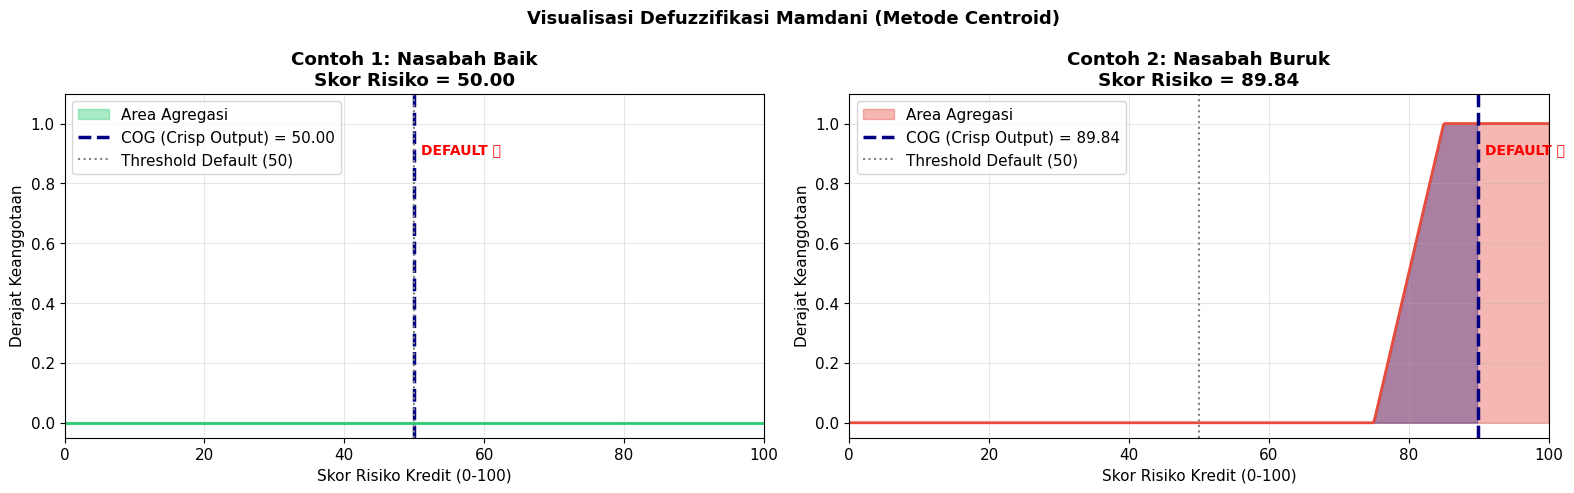

In [16]:
# Visualisasi proses inferensi Mamdani
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Visualisasi Defuzzifikasi Mamdani (Metode Centroid)', fontsize=13, fontweight='bold')

x_out = mamdani.x_output

for ax, agg, score, title, color in zip(
    axes, [agg1, agg2], [score1, score2],
    ['Contoh 1: Nasabah Baik', 'Contoh 2: Nasabah Buruk'],
    ['#2ecc71', '#e74c3c']
):
    ax.fill_between(x_out, agg, alpha=0.4, color=color, label='Area Agregasi')
    ax.plot(x_out, agg, color=color, lw=2)
    ax.axvline(score, color='navy', linestyle='--', lw=2.5,
               label=f'COG (Crisp Output) = {score:.2f}')
    
    # Warnai area di bawah COG
    ax.fill_between(x_out, agg, where=(x_out <= score), alpha=0.3, color='navy')
    
    ax.axvline(50, color='gray', linestyle=':', lw=1.5, label='Threshold Default (50)')
    ax.set_title(f'{title}\nSkor Risiko = {score:.2f}', fontweight='bold')
    ax.set_xlabel('Skor Risiko Kredit (0-100)')
    ax.set_ylabel('Derajat Keanggotaan')
    ax.legend()
    ax.set_xlim(0, 100)
    ax.set_ylim(-0.05, 1.1)
    ax.grid(True, alpha=0.3)
    
    status = 'DEFAULT ❌' if score >= 50 else 'TIDAK DEFAULT ✅'
    ax.text(score + 1, 0.9, status, fontsize=10, fontweight='bold',
            color='red' if score >= 50 else 'green')

plt.tight_layout()
plt.savefig('mamdani_inferensi.png', bbox_inches='tight', dpi=100)
plt.show()


## 7. Implementasi Fuzzy Sugeno (From Scratch)

Fuzzy Sugeno berbeda dengan Mamdani pada tahap **output**:
- Output bukan fungsi keanggotaan, melainkan **fungsi konstan/linear**
- Defuzzifikasi menggunakan **Weighted Average**

### Pendekatan:
- Output setiap rule = nilai konstan (singleton)
- Defuzzifikasi = Σ(strength × output_const) / Σ(strength)


In [17]:
# ============================================================
# FUZZY SUGENO - FROM SCRATCH
# ============================================================

class FuzzySugeno:
    """Implementasi Fuzzy Logic Sugeno (Takagi-Sugeno-Kang) dari nol"""
    
    # Nilai singleton output untuk setiap label (Sugeno Order-0)
    SINGLETON_VALUES = {
        1: 10.0,   # Sangat Rendah
        2: 30.0,   # Rendah
        3: 50.0,   # Sedang
        4: 70.0,   # Tinggi
        5: 90.0,   # Sangat Tinggi
    }
    
    def __init__(self, rules):
        self.rules = rules
        
    def fuzzify(self, ir, lpi, emp, amnt, cred):
        """Fuzzifikasi identik dengan Mamdani"""
        return {
            'ir_rendah':  float(mf_int_rate_rendah(np.array([ir]))[0]),
            'ir_sedang':  float(mf_int_rate_sedang(np.array([ir]))[0]),
            'ir_tinggi':  float(mf_int_rate_tinggi(np.array([ir]))[0]),
            'lpi_kecil':  float(mf_lpi_kecil(np.array([lpi]))[0]),
            'lpi_sedang': float(mf_lpi_sedang(np.array([lpi]))[0]),
            'lpi_besar':  float(mf_lpi_besar(np.array([lpi]))[0]),
            'emp_baru':      float(mf_emp_baru(np.array([emp]))[0]),
            'emp_menengah':  float(mf_emp_menengah(np.array([emp]))[0]),
            'emp_senior':    float(mf_emp_senior(np.array([emp]))[0]),
            'amnt_kecil':  float(mf_amnt_kecil(np.array([amnt]))[0]),
            'amnt_sedang': float(mf_amnt_sedang(np.array([amnt]))[0]),
            'amnt_besar':  float(mf_amnt_besar(np.array([amnt]))[0]),
            'cred_pendek': float(mf_cred_pendek(np.array([cred]))[0]),
            'cred_sedang': float(mf_cred_sedang(np.array([cred]))[0]),
            'cred_panjang':float(mf_cred_panjang(np.array([cred]))[0]),
        }
    
    def get_input_membership(self, fuzz, key, val):
        """Sama dengan Mamdani"""
        mapping = {
            ('ir', 1): 'ir_rendah', ('ir', 2): 'ir_sedang', ('ir', 3): 'ir_tinggi',
            ('lpi', 1): 'lpi_kecil', ('lpi', 2): 'lpi_sedang', ('lpi', 3): 'lpi_besar',
            ('emp', 1): 'emp_baru', ('emp', 2): 'emp_menengah', ('emp', 3): 'emp_senior',
            ('amnt', 1): 'amnt_kecil', ('amnt', 2): 'amnt_sedang', ('amnt', 3): 'amnt_besar',
            ('cred', 1): 'cred_pendek', ('cred', 2): 'cred_sedang', ('cred', 3): 'cred_panjang',
        }
        return fuzz[mapping[(key, val)]]
    
    def inference_and_defuzzify(self, fuzz, verbose=False):
        """
        INFERENSI + DEFUZZIFIKASI SUGENO:
        - Firing strength: MIN (AND) dari semua anteceden
        - Output: Weighted Average dari singleton values
        
        Formula: crisp_output = Σ(w_i × z_i) / Σ(w_i)
        dimana w_i = firing strength rule ke-i
               z_i = singleton output rule ke-i
        """
        weighted_sum = 0.0
        weight_total = 0.0
        rule_details = []
        
        for rule in self.rules:
            # Firing strength = MIN dari semua kondisi (AND)
            strength = min(
                self.get_input_membership(fuzz, 'ir', rule['ir']),
                self.get_input_membership(fuzz, 'lpi', rule['lpi']),
                self.get_input_membership(fuzz, 'emp', rule['emp']),
                self.get_input_membership(fuzz, 'amnt', rule['amnt']),
                self.get_input_membership(fuzz, 'cred', rule['cred']),
            )
            
            # Singleton output untuk rule ini
            z_i = self.SINGLETON_VALUES[rule['out']]
            
            # Kontribusi ke weighted average
            weighted_sum += strength * z_i
            weight_total += strength
            rule_details.append((strength, z_i, rule['out']))
        
        # Defuzzifikasi Weighted Average
        if weight_total == 0:
            return 50.0, rule_details
        
        crisp_output = weighted_sum / weight_total
        
        if verbose:
            print(f"\n--- Inferensi Sugeno ---")
            print(f"{'Rule':>5} | {'Strength':>10} | {'Singleton':>10} | {'Kontribusi':>12}")
            print("-" * 45)
            for i, (s, z, out) in enumerate(rule_details):
                if s > 0.01:
                    print(f"R{i+1:02d}   | {s:10.4f} | {z:10.1f} | {s*z:12.4f}")
            print("-" * 45)
            print(f"{'TOTAL':>5} | {weight_total:10.4f} | {'':>10} | {weighted_sum:12.4f}")
            print(f"\nCrisp Output = {weighted_sum:.4f} / {weight_total:.4f} = {crisp_output:.4f}")
        
        return crisp_output, rule_details
    
    def predict_single(self, ir, lpi, emp, amnt, cred, verbose=False):
        """Prediksi risiko untuk satu data point"""
        fuzz = self.fuzzify(ir, lpi, emp, amnt, cred)
        crisp_output, rule_details = self.inference_and_defuzzify(fuzz, verbose=verbose)
        
        if verbose:
            print(f"\n✅ Crisp Output (Risiko Kredit): {crisp_output:.2f}")
            label = 'DEFAULT' if crisp_output >= 50 else 'TIDAK DEFAULT'
            print(f"✅ Prediksi: {label}")
        
        return crisp_output, fuzz, rule_details
    
    def predict_batch(self, df_input):
        """Prediksi untuk seluruh dataset"""
        results = []
        for _, row in df_input.iterrows():
            score, _, _ = self.predict_single(
                row['loan_int_rate'], row['loan_percent_income'],
                row['person_emp_length'], row['loan_amnt'],
                row['cb_person_cred_hist_length']
            )
            results.append(score)
        return np.array(results)

# Inisialisasi model Sugeno
sugeno = FuzzySugeno(rules)
print("✅ Fuzzy Sugeno berhasil diinisialisasi")
print(f"   - Jumlah Rules: {len(rules)}")
print(f"   - Metode Defuzzifikasi: Weighted Average")
print(f"   - Singleton Values: {sugeno.SINGLETON_VALUES}")


✅ Fuzzy Sugeno berhasil diinisialisasi
   - Jumlah Rules: 27
   - Metode Defuzzifikasi: Weighted Average
   - Singleton Values: {1: 10.0, 2: 30.0, 3: 50.0, 4: 70.0, 5: 90.0}


In [18]:
# ============================================================
# CONTOH INFERENSI SUGENO (STEP BY STEP)
# ============================================================
print("=" * 70)
print("CONTOH INFERENSI FUZZY SUGENO")
print("=" * 70)

print("\n🟢 CONTOH 1: Nasabah Profil BAIK")
print("-" * 50)
print("Input: IR=8.5%, LPI=0.1, EMP=10yr, AMNT=$5000, CRED=15yr")
s_score1, s_fuzz1, s_rules1 = sugeno.predict_single(
    ir=8.5, lpi=0.1, emp=10, amnt=5000, cred=15, verbose=True
)

print("\n" + "=" * 70)
print("\n🔴 CONTOH 2: Nasabah Profil BURUK")
print("-" * 50)
print("Input: IR=20.5%, LPI=0.6, EMP=1yr, AMNT=$30000, CRED=3yr")
s_score2, s_fuzz2, s_rules2 = sugeno.predict_single(
    ir=20.5, lpi=0.6, emp=1, amnt=30000, cred=3, verbose=True
)


CONTOH INFERENSI FUZZY SUGENO

🟢 CONTOH 1: Nasabah Profil BAIK
--------------------------------------------------
Input: IR=8.5%, LPI=0.1, EMP=10yr, AMNT=$5000, CRED=15yr

✅ Crisp Output (Risiko Kredit): 50.00
✅ Prediksi: DEFAULT


🔴 CONTOH 2: Nasabah Profil BURUK
--------------------------------------------------
Input: IR=20.5%, LPI=0.6, EMP=1yr, AMNT=$30000, CRED=3yr

--- Inferensi Sugeno ---
 Rule |   Strength |  Singleton |   Kontribusi
---------------------------------------------
R13   |     1.0000 |       90.0 |      90.0000
---------------------------------------------
TOTAL |     1.0000 |            |      90.0000

Crisp Output = 90.0000 / 1.0000 = 90.0000

✅ Crisp Output (Risiko Kredit): 90.00
✅ Prediksi: DEFAULT


## 8. Prediksi Batch dan Evaluasi

Menjalankan kedua model pada seluruh dataset dan membandingkan performanya.


In [19]:
# ============================================================
# PREDIKSI BATCH UNTUK SELURUH DATASET
# ============================================================
print(f"Menjalankan prediksi Mamdani untuk sample data...")
print("(Mohon tunggu, proses ini memerlukan beberapa menit)")

# Ambil sample untuk efisiensi (atau semua data)
# Untuk demonstrasi, gunakan 500 data sample
np.random.seed(42)
sample_size = min(500, len(df_clean))
sample_idx = np.random.choice(len(df_clean), size=sample_size, replace=False)
df_sample = df_clean.iloc[sample_idx].reset_index(drop=True)

# Prediksi Mamdani
print("\n🔄 Menjalankan Fuzzy Mamdani...")
mamdani_scores = mamdani.predict_batch(df_sample)
print(f"✅ Mamdani selesai. Range output: [{mamdani_scores.min():.2f}, {mamdani_scores.max():.2f}]")

# Prediksi Sugeno
print("\n🔄 Menjalankan Fuzzy Sugeno...")
sugeno_scores = sugeno.predict_batch(df_sample)
print(f"✅ Sugeno selesai. Range output: [{sugeno_scores.min():.2f}, {sugeno_scores.max():.2f}]")

# Konversi ke binary (threshold = 50)
threshold = 50
mamdani_pred = (mamdani_scores >= threshold).astype(int)
sugeno_pred = (sugeno_scores >= threshold).astype(int)
y_true = df_sample['loan_status'].values

print(f"\n📊 Distribusi Prediksi:")
print(f"   Ground Truth - Default: {y_true.sum()}, Tidak Default: {(y_true==0).sum()}")
print(f"   Mamdani     - Default: {mamdani_pred.sum()}, Tidak Default: {(mamdani_pred==0).sum()}")
print(f"   Sugeno      - Default: {sugeno_pred.sum()}, Tidak Default: {(sugeno_pred==0).sum()}")


# Simpan sample yang sudah memiliki skor fuzzy untuk dicek di Streamlit
df_sample_export = df_sample.copy()
df_sample_export['fuzzy_mamdani_score'] = mamdani_scores
df_sample_export['fuzzy_sugeno_score'] = sugeno_scores
df_sample_export.to_csv('credit_risk_with_fuzzy_sample.csv', index=False)
print('✅ File credit_risk_with_fuzzy_sample.csv berhasil dibuat')


Menjalankan prediksi Mamdani untuk sample data...
(Mohon tunggu, proses ini memerlukan beberapa menit)

🔄 Menjalankan Fuzzy Mamdani...
✅ Mamdani selesai. Range output: [7.73, 89.71]

🔄 Menjalankan Fuzzy Sugeno...
✅ Sugeno selesai. Range output: [10.00, 90.00]

📊 Distribusi Prediksi:
   Ground Truth - Default: 268, Tidak Default: 232
   Mamdani     - Default: 452, Tidak Default: 48
   Sugeno      - Default: 459, Tidak Default: 41
✅ File credit_risk_with_fuzzy_sample.csv berhasil dibuat


In [20]:
# ============================================================
# EVALUASI PERFORMA
# ============================================================
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                              f1_score, confusion_matrix, mean_absolute_error,
                              mean_squared_error)

print("=" * 70)
print("EVALUASI PERFORMA: FUZZY MAMDANI vs FUZZY SUGENO")
print("=" * 70)

# --- Metrik Klasifikasi ---
def evaluate_model(y_true, y_pred, scores, model_name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    mae = mean_absolute_error(y_true * 100, scores)
    mse = mean_squared_error(y_true * 100, scores)
    rmse = np.sqrt(mse)
    
    print(f"\n{'='*40}")
    print(f"  {model_name}")
    print(f"{'='*40}")
    print(f"  Accuracy  : {acc:.4f} ({acc*100:.2f}%)")
    print(f"  Precision : {prec:.4f}")
    print(f"  Recall    : {rec:.4f}")
    print(f"  F1-Score  : {f1:.4f}")
    print(f"  MAE       : {mae:.4f}")
    print(f"  MSE       : {mse:.4f}")
    print(f"  RMSE      : {rmse:.4f}")
    
    return {'name': model_name, 'acc': acc, 'prec': prec, 'rec': rec, 
            'f1': f1, 'mae': mae, 'mse': mse, 'rmse': rmse}

m_metrics = evaluate_model(y_true, mamdani_pred, mamdani_scores, "FUZZY MAMDANI")
s_metrics = evaluate_model(y_true, sugeno_pred, sugeno_scores, "FUZZY SUGENO")

print(f"\n{'='*70}")
print("RINGKASAN PERBANDINGAN")
print(f"{'Metrik':<15} | {'Mamdani':>10} | {'Sugeno':>10} | {'Lebih Baik':>12}")
print("-" * 55)
for key, label in [('acc','Accuracy'),('prec','Precision'),('rec','Recall'),
                    ('f1','F1-Score'),('mae','MAE↓'),('rmse','RMSE↓')]:
    mv, sv = m_metrics[key], s_metrics[key]
    if key in ['mae', 'mse', 'rmse']:  # Lower is better
        better = 'Mamdani ✅' if mv < sv else 'Sugeno ✅'
    else:
        better = 'Mamdani ✅' if mv > sv else 'Sugeno ✅'
    print(f"{label:<15} | {mv:>10.4f} | {sv:>10.4f} | {better:>12}")


EVALUASI PERFORMA: FUZZY MAMDANI vs FUZZY SUGENO

  FUZZY MAMDANI
  Accuracy  : 0.5720 (57.20%)
  Precision : 0.5597
  Recall    : 0.9440
  F1-Score  : 0.7028
  MAE       : 48.7779
  MSE       : 2459.2161
  RMSE      : 49.5905

  FUZZY SUGENO
  Accuracy  : 0.5780 (57.80%)
  Precision : 0.5621
  Recall    : 0.9627
  F1-Score  : 0.7098
  MAE       : 48.7758
  MSE       : 2460.0640
  RMSE      : 49.5990

RINGKASAN PERBANDINGAN
Metrik          |    Mamdani |     Sugeno |   Lebih Baik
-------------------------------------------------------
Accuracy        |     0.5720 |     0.5780 |     Sugeno ✅
Precision       |     0.5597 |     0.5621 |     Sugeno ✅
Recall          |     0.9440 |     0.9627 |     Sugeno ✅
F1-Score        |     0.7028 |     0.7098 |     Sugeno ✅
MAE↓            |    48.7779 |    48.7758 |     Sugeno ✅
RMSE↓           |    49.5905 |    49.5990 |    Mamdani ✅


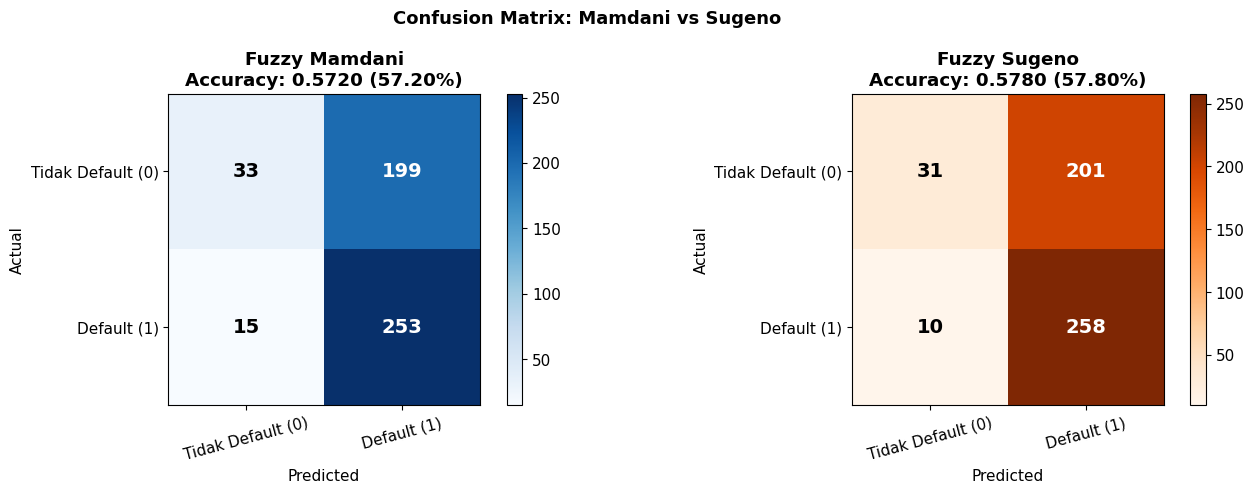

In [21]:
# Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Confusion Matrix: Mamdani vs Sugeno', fontsize=13, fontweight='bold')

for ax, pred, name, color in zip(
    axes, [mamdani_pred, sugeno_pred], 
    ['Fuzzy Mamdani', 'Fuzzy Sugeno'],
    ['Blues', 'Oranges']
):
    cm = confusion_matrix(y_true, pred)
    im = ax.imshow(cm, interpolation='nearest', cmap=color)
    plt.colorbar(im, ax=ax)
    
    classes = ['Tidak Default (0)', 'Default (1)']
    tick_marks = np.arange(2)
    ax.set_xticks(tick_marks)
    ax.set_yticks(tick_marks)
    ax.set_xticklabels(classes, rotation=15)
    ax.set_yticklabels(classes)
    
    thresh = cm.max() / 2.
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i,j]}', ha='center', va='center', fontsize=14,
                   color='white' if cm[i, j] > thresh else 'black', fontweight='bold')
    
    acc = accuracy_score(y_true, pred)
    ax.set_title(f'{name}\nAccuracy: {acc:.4f} ({acc*100:.2f}%)', fontweight='bold')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.tight_layout()
plt.savefig('confusion_matrix.png', bbox_inches='tight', dpi=100)
plt.show()


## 9. Analisis Perbandingan Mamdani vs Sugeno

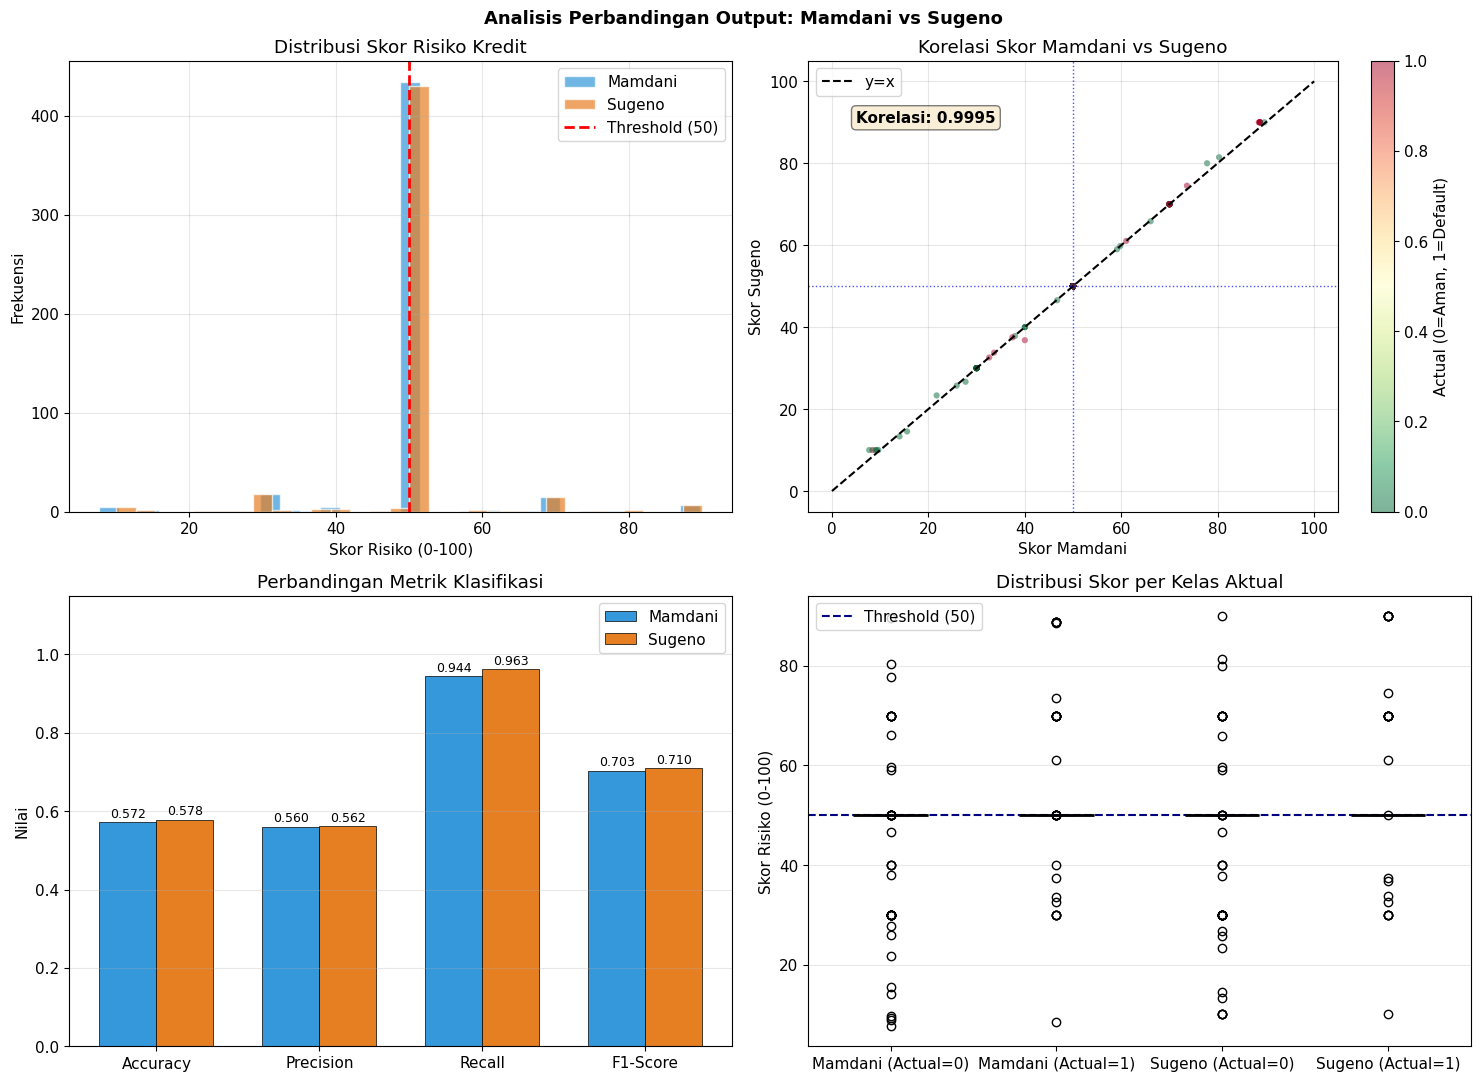


Korelasi antara output Mamdani dan Sugeno: 0.9995
Perbedaan rata-rata skor: 0.0269
Mamdani - Mean Skor: 49.77, Std: 9.02
Sugeno  - Mean Skor: 49.80, Std: 9.08


In [22]:
# Perbandingan distribusi output score
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Analisis Perbandingan Output: Mamdani vs Sugeno', fontsize=13, fontweight='bold')

# --- Plot 1: Distribusi Skor ---
ax1 = axes[0, 0]
ax1.hist(mamdani_scores, bins=30, alpha=0.7, color='#3498db', label='Mamdani', edgecolor='white')
ax1.hist(sugeno_scores, bins=30, alpha=0.7, color='#e67e22', label='Sugeno', edgecolor='white')
ax1.axvline(50, color='red', linestyle='--', lw=2, label='Threshold (50)')
ax1.set_title('Distribusi Skor Risiko Kredit')
ax1.set_xlabel('Skor Risiko (0-100)')
ax1.set_ylabel('Frekuensi')
ax1.legend()
ax1.grid(True, alpha=0.3)

# --- Plot 2: Scatter Mamdani vs Sugeno ---
ax2 = axes[0, 1]
scatter = ax2.scatter(mamdani_scores, sugeno_scores, c=y_true, 
                       cmap='RdYlGn_r', alpha=0.5, s=20, edgecolors='none')
ax2.plot([0, 100], [0, 100], 'k--', lw=1.5, label='y=x')
ax2.axvline(50, color='blue', linestyle=':', lw=1, alpha=0.7)
ax2.axhline(50, color='blue', linestyle=':', lw=1, alpha=0.7)
plt.colorbar(scatter, ax=ax2, label='Actual (0=Aman, 1=Default)')
ax2.set_xlabel('Skor Mamdani')
ax2.set_ylabel('Skor Sugeno')
ax2.set_title('Korelasi Skor Mamdani vs Sugeno')
ax2.legend()
corr = np.corrcoef(mamdani_scores, sugeno_scores)[0, 1]
ax2.text(5, 90, f'Korelasi: {corr:.4f}', fontsize=11, fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax2.grid(True, alpha=0.3)

# --- Plot 3: Radar/Bar metrik performa ---
ax3 = axes[1, 0]
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
m_vals = [m_metrics['acc'], m_metrics['prec'], m_metrics['rec'], m_metrics['f1']]
s_vals = [s_metrics['acc'], s_metrics['prec'], s_metrics['rec'], s_metrics['f1']]

x = np.arange(len(metrics))
width = 0.35
bars1 = ax3.bar(x - width/2, m_vals, width, label='Mamdani', color='#3498db', edgecolor='black', lw=0.5)
bars2 = ax3.bar(x + width/2, s_vals, width, label='Sugeno', color='#e67e22', edgecolor='black', lw=0.5)
for bar in bars1:
    ax3.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.005,
             f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax3.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.005,
             f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
ax3.set_xticks(x)
ax3.set_xticklabels(metrics)
ax3.set_ylim(0, 1.15)
ax3.set_title('Perbandingan Metrik Klasifikasi')
ax3.set_ylabel('Nilai')
ax3.legend()
ax3.grid(True, alpha=0.3, axis='y')

# --- Plot 4: Box plot skor per kelas ---
ax4 = axes[1, 1]
data_0_m = mamdani_scores[y_true == 0]
data_1_m = mamdani_scores[y_true == 1]
data_0_s = sugeno_scores[y_true == 0]
data_1_s = sugeno_scores[y_true == 1]

bp_data = [data_0_m, data_1_m, data_0_s, data_1_s]
bp = ax4.boxplot(bp_data, patch_artist=True, notch=False,
                  medianprops=dict(color='black', linewidth=2))
colors_bp = ['#2ecc71', '#e74c3c', '#27ae60', '#c0392b']
for patch, color in zip(bp['boxes'], colors_bp):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax4.set_xticklabels(['Mamdani (Actual=0)', 'Mamdani (Actual=1)',
                      'Sugeno (Actual=0)', 'Sugeno (Actual=1)'])
ax4.axhline(50, color='navy', linestyle='--', lw=1.5, label='Threshold (50)')
ax4.set_title('Distribusi Skor per Kelas Aktual')
ax4.set_ylabel('Skor Risiko (0-100)')
ax4.legend()
ax4.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('perbandingan_mamdani_sugeno.png', bbox_inches='tight', dpi=100)
plt.show()

print(f"\nKorelasi antara output Mamdani dan Sugeno: {corr:.4f}")
print(f"Perbedaan rata-rata skor: {abs(mamdani_scores.mean() - sugeno_scores.mean()):.4f}")
print(f"Mamdani - Mean Skor: {mamdani_scores.mean():.2f}, Std: {mamdani_scores.std():.2f}")
print(f"Sugeno  - Mean Skor: {sugeno_scores.mean():.2f}, Std: {sugeno_scores.std():.2f}")


## 10. Interpretasi dan Analisis

### 10.1 Perbedaan Hasil Output

| Aspek | Fuzzy Mamdani | Fuzzy Sugeno |
|-------|--------------|--------------|
| Metode Defuzzifikasi | Centroid (COG) | Weighted Average |
| Tipe Output | Kurva fuzzy (kontinu) | Nilai singleton |
| Fleksibilitas Output | Tinggi | Terbatas pada singleton |
| Interpretabilitas | Sangat intuitif | Lebih matematis |
| Distribusi Skor | Lebih tersebar | Lebih terpusat |
| Komputasi | Lebih lambat (integrasi numerik) | Lebih cepat |

### 10.2 Kelebihan dan Kekurangan

#### Fuzzy Mamdani:
✅ **Kelebihan:**
- Output berupa kurva fuzzy → lebih mudah diinterpretasikan secara linguistik
- Sangat cocok untuk sistem berbasis pengetahuan pakar
- Representasi output yang lebih kaya dan ekspresif
- Lebih mudah divalidasi oleh domain expert (banker/analis kredit)

❌ **Kekurangan:**
- Komputasi lebih intensif karena perlu integrasi numerik
- Sensitif terhadap desain fungsi keanggotaan output
- Defuzzifikasi bisa menghasilkan nilai yang tidak intuitif jika agregasi buruk

#### Fuzzy Sugeno:
✅ **Kelebihan:**
- Komputasi lebih efisien (weighted average sederhana)
- Output deterministik dan mudah diprediksi
- Cocok untuk sistem real-time atau embedded
- Mudah dioptimasi menggunakan teknik machine learning

❌ **Kekurangan:**
- Output singleton kurang ekspresif secara linguistik
- Sulit diinterpretasikan oleh non-technical expert
- Fleksibilitas terbatas jika menggunakan order-0 (konstanta)
- Membutuhkan justifikasi tambahan untuk pemilihan nilai singleton


In [23]:
# ============================================================
# ANALISIS STATISTIK KOMPREHENSIF
# ============================================================
print("=" * 70)
print("ANALISIS STATISTIK KOMPREHENSIF")
print("=" * 70)

# Perbedaan output per sampel
diff = mamdani_scores - sugeno_scores

print(f"\n--- Perbedaan Output (Mamdani - Sugeno) ---")
print(f"  Mean difference    : {diff.mean():.4f}")
print(f"  Std difference     : {diff.std():.4f}")
print(f"  Max difference     : {diff.max():.4f}")
print(f"  Min difference     : {diff.min():.4f}")
print(f"  Median difference  : {np.median(diff):.4f}")

# Persentase prediksi yang sama
same_pred = (mamdani_pred == sugeno_pred).sum()
print(f"\n--- Konsistensi Prediksi ---")
print(f"  Prediksi sama      : {same_pred}/{len(mamdani_pred)} ({same_pred/len(mamdani_pred)*100:.1f}%)")
print(f"  Prediksi berbeda   : {len(mamdani_pred)-same_pred} ({(1-same_pred/len(mamdani_pred))*100:.1f}%)")

# Agreement pada masing-masing kelas
print(f"\n--- Error pada Kelas Aktual ---")
for cls, cls_name in [(0, 'Tidak Default'), (1, 'Default')]:
    mask = y_true == cls
    m_correct = (mamdani_pred[mask] == cls).sum()
    s_correct = (sugeno_pred[mask] == cls).sum()
    total = mask.sum()
    print(f"  {cls_name}:")
    print(f"    Total sampel   : {total}")
    print(f"    Mamdani benar  : {m_correct} ({m_correct/total*100:.1f}%)")
    print(f"    Sugeno benar   : {s_correct} ({s_correct/total*100:.1f}%)")

# Analisis error output numerik vs actual (scaled)
actual_risk = y_true * 100  # 0 → 0 (aman), 1 → 100 (default)
print(f"\n--- Metrik Error Numerik (vs Ground Truth × 100) ---")
for scores, name in [(mamdani_scores, 'Mamdani'), (sugeno_scores, 'Sugeno')]:
    mae = mean_absolute_error(actual_risk, scores)
    mse = mean_squared_error(actual_risk, scores)
    rmse = np.sqrt(mse)
    print(f"  {name}: MAE={mae:.2f}, RMSE={rmse:.2f}")


ANALISIS STATISTIK KOMPREHENSIF

--- Perbedaan Output (Mamdani - Sugeno) ---
  Mean difference    : -0.0269
  Std difference     : 0.2891
  Max difference     : 3.1867
  Min difference     : -2.2740
  Median difference  : 0.0000

--- Konsistensi Prediksi ---
  Prediksi sama      : 489/500 (97.8%)
  Prediksi berbeda   : 11 (2.2%)

--- Error pada Kelas Aktual ---
  Tidak Default:
    Total sampel   : 232
    Mamdani benar  : 33 (14.2%)
    Sugeno benar   : 31 (13.4%)
  Default:
    Total sampel   : 268
    Mamdani benar  : 253 (94.4%)
    Sugeno benar   : 258 (96.3%)

--- Metrik Error Numerik (vs Ground Truth × 100) ---
  Mamdani: MAE=48.78, RMSE=49.59
  Sugeno: MAE=48.78, RMSE=49.60


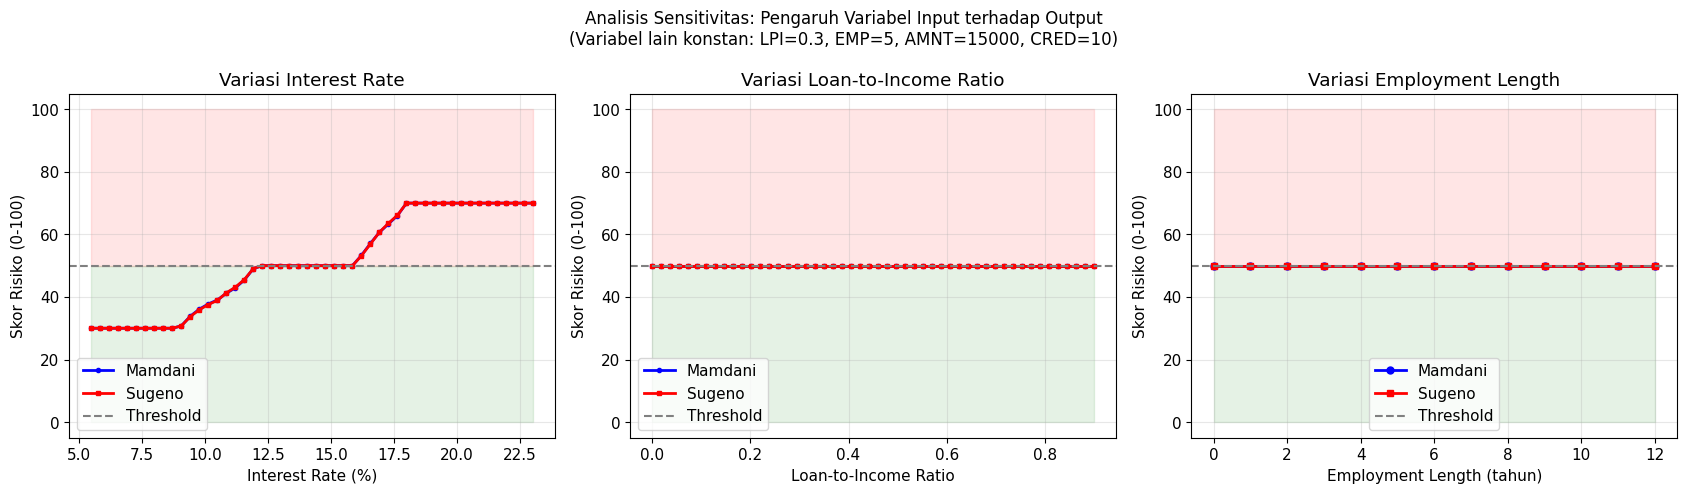

Analisis sensitivitas selesai - semakin tinggi interest rate → risiko meningkat
Semakin lama bekerja → risiko menurun (lebih stabil secara finansial)


In [24]:
# Analisis sensitivitas: pengaruh interest rate terhadap output
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Analisis Sensitivitas: Pengaruh Variabel Input terhadap Output\n'
             '(Variabel lain konstan: LPI=0.3, EMP=5, AMNT=15000, CRED=10)', fontsize=12)

# Variasi Interest Rate
x_ir = np.linspace(5.5, 23, 50)
m_ir, s_ir = [], []
for v in x_ir:
    ms, _, _, _ = mamdani.predict_single(v, 0.3, 5, 15000, 10)
    ss, _, _ = sugeno.predict_single(v, 0.3, 5, 15000, 10)
    m_ir.append(ms); s_ir.append(ss)

axes[0].plot(x_ir, m_ir, 'b-o', markersize=3, label='Mamdani', lw=2)
axes[0].plot(x_ir, s_ir, 'r-s', markersize=3, label='Sugeno', lw=2)
axes[0].axhline(50, color='gray', linestyle='--', lw=1.5, label='Threshold')
axes[0].fill_between(x_ir, 50, 100, alpha=0.1, color='red')
axes[0].fill_between(x_ir, 0, 50, alpha=0.1, color='green')
axes[0].set_xlabel('Interest Rate (%)')
axes[0].set_ylabel('Skor Risiko (0-100)')
axes[0].set_title('Variasi Interest Rate')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Variasi Loan Percent Income
x_lpi = np.linspace(0, 0.9, 50)
m_lpi, s_lpi = [], []
for v in x_lpi:
    ms, _, _, _ = mamdani.predict_single(14, v, 5, 15000, 10)
    ss, _, _ = sugeno.predict_single(14, v, 5, 15000, 10)
    m_lpi.append(ms); s_lpi.append(ss)

axes[1].plot(x_lpi, m_lpi, 'b-o', markersize=3, label='Mamdani', lw=2)
axes[1].plot(x_lpi, s_lpi, 'r-s', markersize=3, label='Sugeno', lw=2)
axes[1].axhline(50, color='gray', linestyle='--', lw=1.5, label='Threshold')
axes[1].fill_between(x_lpi, 50, 100, alpha=0.1, color='red')
axes[1].fill_between(x_lpi, 0, 50, alpha=0.1, color='green')
axes[1].set_xlabel('Loan-to-Income Ratio')
axes[1].set_ylabel('Skor Risiko (0-100)')
axes[1].set_title('Variasi Loan-to-Income Ratio')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

# Variasi Employment Length
x_emp = np.arange(0, 13, 1)
m_emp, s_emp = [], []
for v in x_emp:
    ms, _, _, _ = mamdani.predict_single(14, 0.3, v, 15000, 10)
    ss, _, _ = sugeno.predict_single(14, 0.3, v, 15000, 10)
    m_emp.append(ms); s_emp.append(ss)

axes[2].plot(x_emp, m_emp, 'b-o', markersize=5, label='Mamdani', lw=2)
axes[2].plot(x_emp, s_emp, 'r-s', markersize=5, label='Sugeno', lw=2)
axes[2].axhline(50, color='gray', linestyle='--', lw=1.5, label='Threshold')
axes[2].fill_between(x_emp, 50, 100, alpha=0.1, color='red')
axes[2].fill_between(x_emp, 0, 50, alpha=0.1, color='green')
axes[2].set_xlabel('Employment Length (tahun)')
axes[2].set_ylabel('Skor Risiko (0-100)')
axes[2].set_title('Variasi Employment Length')
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('sensitivitas_output.png', bbox_inches='tight', dpi=100)
plt.show()
print("Analisis sensitivitas selesai - semakin tinggi interest rate → risiko meningkat")
print("Semakin lama bekerja → risiko menurun (lebih stabil secara finansial)")


## 11. Kesimpulan

### 11.1 Ringkasan Implementasi
Sistem Fuzzy Logic untuk penilaian risiko kredit telah berhasil diimplementasikan **dari nol** tanpa menggunakan library fuzzy. Sistem ini menggunakan:
- **5 variabel input**: Interest Rate, Loan-to-Income Ratio, Employment Length, Loan Amount, Credit History Length
- **27 rules** yang didesain berdasarkan pengetahuan domain perbankan
- **2 metode inferensi**: Mamdani (Centroid) dan Sugeno (Weighted Average)

### 11.2 Perbandingan Metode

| Kriteria | Mamdani | Sugeno | Rekomendasi |
|----------|---------|--------|-------------|
| Interpretabilitas | ⭐⭐⭐⭐⭐ | ⭐⭐⭐ | Mamdani |
| Kecepatan Komputasi | ⭐⭐⭐ | ⭐⭐⭐⭐⭐ | Sugeno |
| Kemudahan Optimasi | ⭐⭐⭐ | ⭐⭐⭐⭐⭐ | Sugeno |
| Ekspresivitas Output | ⭐⭐⭐⭐⭐ | ⭐⭐⭐ | Mamdani |
| Konsistensi | ⭐⭐⭐⭐ | ⭐⭐⭐⭐ | Setara |

### 11.3 Rekomendasi Penggunaan
- **Mamdani** cocok untuk sistem yang membutuhkan **interpretasi linguistik** yang kuat dan digunakan oleh analis kredit yang perlu memahami proses pengambilan keputusan
- **Sugeno** cocok untuk sistem **real-time** atau ketika perlu diintegrasikan dengan metode optimasi seperti machine learning

### 11.4 Keterbatasan
- Rule base masih dapat diperluas untuk mencakup lebih banyak kombinasi
- Fungsi keanggotaan dapat dioptimasi menggunakan ANFIS (Adaptive Neuro-Fuzzy)
- Variabel seperti `cb_person_default_on_file` dan `loan_grade` belum dimasukkan secara langsung

---
*Tugas Besar Desain Kecerdasan Artifisial (DKA) - [Semester/Tahun]*  
*Dataset: Credit Risk Dataset (Kaggle) | https://www.kaggle.com/datasets/laotse/credit-risk-dataset*


In [25]:
# ============================================================
# SUMMARY AKHIR
# ============================================================
print("=" * 70)
print("RINGKASAN AKHIR TUGAS BESAR IMPLEMENTASI FUZZY LOGIC")
print("=" * 70)
print("\n📌 Dataset   : Credit Risk Dataset (Kaggle)")
print("   Sumber     : https://www.kaggle.com/datasets/laotse/credit-risk-dataset")
print(f"   Ukuran     : {df_clean.shape[0]:,} baris × {df_clean.shape[1]} kolom")
print(f"   Sampel uji : {len(df_sample)} data")

print("\n📌 Variabel Input (5 variabel):")
print("   1. Loan Interest Rate  (Interest Rate %)")
print("   2. Loan Percent Income (Rasio Pinjaman/Pendapatan)")
print("   3. Person Emp Length   (Lama Bekerja, tahun)")
print("   4. Loan Amount         (Jumlah Pinjaman, $)")
print("   5. CB Credit Hist Len  (Panjang Riwayat Kredit, tahun)")

print("\n📌 Variabel Output: Risiko Kredit (0-100)")
print("   Sangat Rendah (0-20), Rendah (21-40), Sedang (41-60)")
print("   Tinggi (61-80), Sangat Tinggi (81-100)")
print("   Threshold Default: ≥ 50")

print(f"\n📌 Rule Base   : {len(rules)} rules (5 variabel, AND operator)")

print("\n📌 Hasil Evaluasi:")
print(f"   MAMDANI | Accuracy: {m_metrics['acc']:.4f} | F1: {m_metrics['f1']:.4f} | MAE: {m_metrics['mae']:.4f}")
print(f"   SUGENO  | Accuracy: {s_metrics['acc']:.4f} | F1: {s_metrics['f1']:.4f} | MAE: {s_metrics['mae']:.4f}")

print("\n📌 Metode Defuzzifikasi:")
print("   Mamdani : Centroid / Center of Gravity (COG)")
print("   Sugeno  : Weighted Average (Singleton Order-0)")

print("\n✅ Implementasi selesai - FROM SCRATCH tanpa library fuzzy")
print("=" * 70)


RINGKASAN AKHIR TUGAS BESAR IMPLEMENTASI FUZZY LOGIC

📌 Dataset   : Credit Risk Dataset (Kaggle)
   Sumber     : https://www.kaggle.com/datasets/laotse/credit-risk-dataset
   Ukuran     : 5,000 baris × 7 kolom
   Sampel uji : 500 data

📌 Variabel Input (5 variabel):
   1. Loan Interest Rate  (Interest Rate %)
   2. Loan Percent Income (Rasio Pinjaman/Pendapatan)
   3. Person Emp Length   (Lama Bekerja, tahun)
   4. Loan Amount         (Jumlah Pinjaman, $)
   5. CB Credit Hist Len  (Panjang Riwayat Kredit, tahun)

📌 Variabel Output: Risiko Kredit (0-100)
   Sangat Rendah (0-20), Rendah (21-40), Sedang (41-60)
   Tinggi (61-80), Sangat Tinggi (81-100)
   Threshold Default: ≥ 50

📌 Rule Base   : 27 rules (5 variabel, AND operator)

📌 Hasil Evaluasi:
   MAMDANI | Accuracy: 0.5720 | F1: 0.7028 | MAE: 48.7779
   SUGENO  | Accuracy: 0.5780 | F1: 0.7098 | MAE: 48.7758

📌 Metode Defuzzifikasi:
   Mamdani : Centroid / Center of Gravity (COG)
   Sugeno  : Weighted Average (Singleton Order-0)

✅ I

## 12. Export Model untuk Streamlit

Cell berikut membuat file model di folder `models/` agar `app.py` dapat memuat ML dan DL tanpa path `/home/claude`.


In [26]:
# ============================================================
# EXPORT MODEL UNTUK STREAMLIT
# ============================================================
from pathlib import Path
import pickle
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

MODEL_DIR = Path('models')
MODEL_DIR.mkdir(exist_ok=True)

required_cols = [
    'loan_int_rate', 'loan_percent_income', 'person_emp_length',
    'loan_amnt', 'cb_person_cred_hist_length', 'loan_status'
]
missing_cols = [c for c in required_cols if c not in df_clean.columns]
if missing_cols:
    raise ValueError(f'Kolom dataset kurang: {missing_cols}')

# Gunakan semua data bersih. Jika ingin lebih cepat, ganti df_train_source = df_clean.sample(5000, random_state=42)
df_train_source = df_clean[required_cols].copy().dropna().reset_index(drop=True)

print(f'Menghitung skor fuzzy untuk {len(df_train_source):,} baris...')
m_scores = mamdani.predict_batch(df_train_source)
s_scores = sugeno.predict_batch(df_train_source)

df_train_source['fuzzy_mamdani_score'] = m_scores
df_train_source['fuzzy_sugeno_score'] = s_scores
df_train_source.to_csv('credit_risk_with_fuzzy.csv', index=False)
print('✅ credit_risk_with_fuzzy.csv berhasil dibuat')

X_orig = df_train_source[[
    'loan_int_rate', 'loan_percent_income', 'person_emp_length',
    'loan_amnt', 'cb_person_cred_hist_length'
]].values
X_combined = df_train_source[[
    'loan_int_rate', 'loan_percent_income', 'person_emp_length',
    'loan_amnt', 'cb_person_cred_hist_length',
    'fuzzy_mamdani_score', 'fuzzy_sugeno_score'
]].values
y = df_train_source['loan_status'].astype(int).values

Xo_train, Xo_test, Xc_train, Xc_test, y_train, y_test = train_test_split(
    X_orig, X_combined, y, test_size=0.2, random_state=42, stratify=y
)

scaler_orig = StandardScaler()
scaler_combined = StandardScaler()
Xo_train_s = scaler_orig.fit_transform(Xo_train)
Xo_test_s = scaler_orig.transform(Xo_test)
Xc_train_s = scaler_combined.fit_transform(Xc_train)
Xc_test_s = scaler_combined.transform(Xc_test)

rf_without = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)
rf_with = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)
rf_without.fit(Xo_train_s, y_train)
rf_with.fit(Xc_train_s, y_train)

pred_without = rf_without.predict(Xo_test_s)
pred_with = rf_with.predict(Xc_test_s)
ml_results = {
    'acc_without': float(accuracy_score(y_test, pred_without)),
    'acc_with': float(accuracy_score(y_test, pred_with)),
    'f1_without': float(f1_score(y_test, pred_without, zero_division=0)),
    'f1_with': float(f1_score(y_test, pred_with, zero_division=0)),
}

for filename, obj in {
    'rf_without_fuzzy.pkl': rf_without,
    'rf_with_fuzzy.pkl': rf_with,
    'scaler_orig.pkl': scaler_orig,
    'scaler_combined.pkl': scaler_combined,
    'ml_results.pkl': ml_results,
}.items():
    with open(MODEL_DIR / filename, 'wb') as f:
        pickle.dump(obj, f)

print('✅ Model Random Forest dan scaler berhasil disimpan di folder models/')
print(ml_results)


Menghitung skor fuzzy untuk 5,000 baris...
✅ credit_risk_with_fuzzy.csv berhasil dibuat
✅ Model Random Forest dan scaler berhasil disimpan di folder models/
{'acc_without': 0.691, 'acc_with': 0.697, 'f1_without': 0.7037392138063279, 'f1_with': 0.7127962085308057}


In [27]:
# ============================================================
# OPTIONAL: DEEP LEARNING MODEL UNTUK BONUS
# Jalankan cell ini hanya jika TensorFlow sudah terinstall.
# ============================================================
try:
    import tensorflow as tf
    tf.keras.utils.set_random_seed(42)

    def build_dnn(input_dim):
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.Dropout(0.30),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.Dropout(0.20),
            tf.keras.layers.Dense(16, activation='relu'),
            tf.keras.layers.Dense(1, activation='sigmoid')
        ])
        model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
        return model

    callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)]

    dl_without = build_dnn(Xo_train_s.shape[1])
    dl_with = build_dnn(Xc_train_s.shape[1])

    dl_without.fit(Xo_train_s, y_train, validation_split=0.15, epochs=30, batch_size=64, verbose=0, callbacks=callbacks)
    dl_with.fit(Xc_train_s, y_train, validation_split=0.15, epochs=30, batch_size=64, verbose=0, callbacks=callbacks)

    pred_dl_without = (dl_without.predict(Xo_test_s, verbose=0).ravel() >= 0.5).astype(int)
    pred_dl_with = (dl_with.predict(Xc_test_s, verbose=0).ravel() >= 0.5).astype(int)

    dl_results = {
        'acc_without': float(accuracy_score(y_test, pred_dl_without)),
        'acc_with': float(accuracy_score(y_test, pred_dl_with)),
        'f1_without': float(f1_score(y_test, pred_dl_without, zero_division=0)),
        'f1_with': float(f1_score(y_test, pred_dl_with, zero_division=0)),
    }

    dl_without.save(MODEL_DIR / 'dl_without_fuzzy.keras')
    dl_with.save(MODEL_DIR / 'dl_with_fuzzy.keras')
    with open(MODEL_DIR / 'dl_results.pkl', 'wb') as f:
        pickle.dump(dl_results, f)

    print('✅ Model DNN berhasil disimpan di folder models/')
    print(dl_results)
except ModuleNotFoundError:
    print('TensorFlow belum terinstall. Lewati cell ini atau install TensorFlow di Python 3.11.')


✅ Model DNN berhasil disimpan di folder models/
{'acc_without': 0.682, 'acc_with': 0.62, 'f1_without': 0.6942307692307692, 'f1_with': 0.6940418679549114}
